# Student Dropout Prediction — Integrated Analysis

This notebook consolidates exploratory analysis, preprocessing, initial model comparison, tuning, ensembles, feature-group comparisons, and permutation importance. It replaces repeated setup with one dataset and one stratified split. The final section evaluates the frozen selected model on the held-out test set.

**Scope:** model development uses 3,539 training records; the final evaluation uses the 885 held-out records only after the selected configuration is fixed. The final configuration is embedded so the notebook does not need a separate configuration file. Do not tune or change the model based on test results. The development workflow is unchanged; the appended evaluation was checked separately against the verified standalone script. This integrated notebook has not been rerun from start to finish.

Run cells in order with Python, pandas, NumPy, SciPy, scikit-learn, XGBoost, Matplotlib, seaborn (0.13 or later), IPython, and tabulate. Place the repository dataset ZIP or `data.csv` beside this notebook or in its parent directory. Outputs go to `combined_results/`, preserving the original result filenames in separate subdirectories. Exact historical dependency versions are unavailable; reruns may differ.


## 1. Imports and settings


In [53]:
from pathlib import Path
import io, json, zipfile, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.stats import loguniform, randint, uniform
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import GradientBoostingClassifier, VotingClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    make_scorer,
    recall_score,
    accuracy_score,
    f1_score
)
from sklearn.model_selection import StratifiedKFold, RandomizedSearchCV, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, LabelEncoder, OneHotEncoder, StandardScaler
from xgboost import XGBClassifier
RANDOM_STATE = 42
FAST_MODE = False
N_SPLITS = 5
N_PERM_REPEATS = 2 if FAST_MODE else 4
ITERATIONS = {'XGBoost': 3 if FAST_MODE else 10, 'Gradient Boosting': 3 if FAST_MODE else 10, 'Logistic Regression': 3 if FAST_MODE else 8}
CV = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE)
RESULTS_ROOT = Path('combined_results').resolve()
EDA_DIR = RESULTS_ROOT / 'eda'
OUTPUT_DIR = RESULTS_ROOT / 'part_e_results'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
import hashlib
import matplotlib
import seaborn as sns
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import precision_score, classification_report, confusion_matrix, ConfusionMatrixDisplay


## 2. Read data once and reserve the test set

The split uses the original row order, stratification on Target, and seed 42. The original CSV bytes are hashed. The test set is retained for subsequent final evaluation but is not scored here.


In [2]:
search_dirs = list(dict.fromkeys([Path.cwd(), Path.cwd().parent, Path.cwd().parent.parent, Path.cwd() / 'insy674_partb_result']))
zip_candidates = []
csv_candidates = []
for parent in search_dirs:
    if parent.exists():
        zip_candidates.extend(sorted(parent.glob('predict*students*dropout*.zip')))
        csv_candidates.extend([parent / 'data.csv'])

def load_dataset():
    for path in zip_candidates:
        if not path.is_file():
            continue
        with zipfile.ZipFile(path) as archive:
            names = [n for n in archive.namelist() if Path(n).name.lower() == 'data.csv']
            if names:
                raw_bytes = archive.read(names[0])
                data = pd.read_csv(io.BytesIO(raw_bytes), sep=';', encoding='utf-8-sig')
                return (data, f'{path} -> {names[0]}', raw_bytes)
    for path in csv_candidates:
        if path.is_file():
            return (pd.read_csv(path, sep=';', encoding='utf-8-sig'), str(path), path.read_bytes())
    raise FileNotFoundError('Cannot locate the repository dataset ZIP or data.csv. Run from the repo root or put data.csv beside this notebook.')
(df, DATA_SOURCE, DATA_BYTES) = load_dataset()
df.columns = df.columns.str.strip().str.replace('\ufeff', '', regex=False)
assert 'Target' in df.columns, 'Expected a Target column.'
assert set(df['Target'].unique()) == {'Dropout', 'Enrolled', 'Graduate'}
print('Data:', DATA_SOURCE, '| shape:', df.shape)
print('Labels:', df['Target'].value_counts().to_dict())
row_ids = np.arange(len(df))
(train_ids, test_ids) = train_test_split(row_ids, test_size=0.2, random_state=RANDOM_STATE, stratify=df['Target'])
X = df.drop(columns=['Target'])
y = df['Target']
(X_train, X_test) = (X.iloc[train_ids].copy(), X.iloc[test_ids].copy())
(y_train, y_test) = (y.iloc[train_ids].copy(), y.iloc[test_ids].copy())
assert not set(train_ids).intersection(test_ids)
assert len(df) == 4424 and len(train_ids) == 3539 and (len(test_ids) == 885)
print('Training:', len(train_ids), '| Reserved test:', len(test_ids))


Data: /Users/katherine/INSY 674 Raghav/predict+students+dropout+and+academic+success (2).zip -> data.csv | shape: (4424, 37)
Labels: {'Graduate': 2209, 'Dropout': 1421, 'Enrolled': 794}
Training: 3539 | Reserved test: 885


## 3. Exploratory data analysis

All outcome-related summaries and six figures use training rows. Full-file duplicate checks are structural checks. Second-semester values are excluded from substantive EDA. Macroeconomic variables are descriptive context only; later models exclude them.


In [3]:
ROOT = EDA_DIR
ROOT.mkdir(parents=True, exist_ok=True)
for folder in ['figures', 'tables', 'reports']:
    (ROOT / folder).mkdir(exist_ok=True)
ORDER = ['Dropout', 'Enrolled', 'Graduate']
COLORS = ['#C65B51', '#D5A541', '#32818A']
FIN = ['Scholarship holder', 'Debtor', 'Tuition fees up to date']
CAT = ['Marital status', 'Application mode', 'Course', 'Daytime/evening attendance', 'Previous qualification', 'Nacionality', "Mother's qualification", "Father's qualification", "Mother's occupation", "Father's occupation", 'Displaced', 'Educational special needs', 'Debtor', 'Tuition fees up to date', 'Gender', 'Scholarship holder', 'International']
NUM = ['Previous qualification (grade)', 'Admission grade', 'Age at enrollment', 'Unemployment rate', 'Inflation rate', 'GDP', 'Application order']
SOURCE = 'https://archive.ics.uci.edu/dataset/697/predict+students+dropout+and+academic+success'

def md(df):

    def clean(x):
        return str(x).replace('|', '/').replace('\n', ' ')
    return '| ' + ' | '.join(map(clean, df.columns)) + ' |\n|' + '|'.join(['---'] * len(df.columns)) + '|\n' + '\n'.join(('| ' + ' | '.join(map(clean, row)) + ' |' for row in df.itertuples(index=False, name=None)))

def save(name):
    plt.savefig(ROOT / 'figures' / f'{name}.png', dpi=180, bbox_inches='tight')
    display((fig := plt.gcf()))
    plt.close(fig)


### 3.1 Preserve the shared split

Export row assignments for reproducibility. All subsequent exploration uses training rows.


In [4]:
d = df.copy()
ids = row_ids
tr, te = train_ids, test_ids
# Export assignment only: original CSV row positions are identifiers, not predictors.
assignment=pd.DataFrame({'row_id':ids,'split':np.where(np.isin(ids,tr),'train','test')})
assignment.to_csv(ROOT/'tables/split_assignments.csv',index=False)
x=d.iloc[tr].copy()
features=[c for c in d if c!='Target']
second=[c for c in features if '2nd sem' in c]
first=[c for c in features if '1st sem' in c]
eligible=[c for c in features if c not in second]
numeric=[c for c in eligible if c not in CAT]


### 3.2 Outcome distribution

Count Dropout, Enrolled, and Graduate students and draw the first figure.


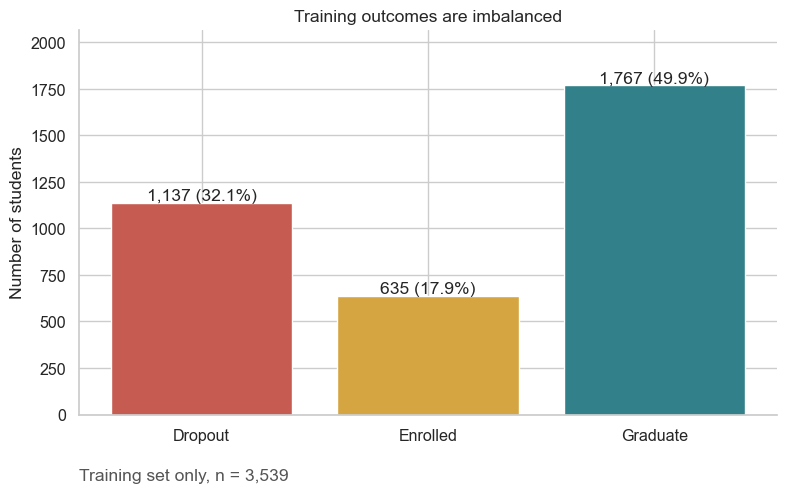

In [5]:
sns.set_theme(style='whitegrid',font_scale=1.05)
plt.rcParams.update({'axes.spines.top':False,'axes.spines.right':False,'figure.figsize':(9,5)})
counts=x.Target.value_counts().reindex(ORDER)
ct=pd.DataFrame({'Status':ORDER,'n':counts.values,'Percent':(100*counts/len(x)).round(2).values})
ct.to_csv(ROOT/'tables/class_distribution.csv',index=False)
fig,ax=plt.subplots()
bars=ax.bar(ORDER,counts,color=COLORS)
for b,n in zip(bars,counts): ax.text(b.get_x()+b.get_width()/2,n+15,f'{n:,} ({n/len(x):.1%})',ha='center')
ax.set(title='Training outcomes are imbalanced',ylabel='Number of students',ylim=(0,max(counts)*1.17))
ax.text(0,-.17,f'Training set only, n = {len(x):,}',transform=ax.transAxes,color='#555555')
save('01_target_distribution')


### 3.3 Attribute profiling and data quality

Profile categories, missingness, ranges, and unknown codes. Second-semester values remain excluded.


In [6]:
rows = []
for c in features:
    excluded = c in second
    s = x[c]
    role = 'Financial' if c in FIN else 'Academic' if c in first or c in ['Admission grade', 'Previous qualification', 'Previous qualification (grade)'] else 'Context'
    timing = 'Excluded: after prediction horizon' if excluded else 'End of first semester' if c in first else 'Enrollment candidate; verify administrative timing'
    note = 'Do not interpret numeric codes as continuous.' if c in CAT else 'Inspect skew and extremes; retain valid observations.'
    if c in ["Mother's qualification", "Father's qualification"]:
        note += f' Unknown code 34: {int((s == 34).sum())} ({(s == 34).mean():.1%}).'
    if '(grade)' in c and 'sem' in c:
        note += ' Zero grade may indicate no successful assessment; do not replace with missing automatically.'
    if c in FIN:
        note += ' Recording date unconfirmed; early-availability assumption must be documented.'
    rows.append({'feature': c, 'group': role, 'semantic_type': 'Categorical code' if c in CAT else 'Count' if c in first or c in second else 'Numeric/ordinal', 'timing': timing, 'missing_pct': round(s.isna().mean() * 100, 3) if not excluded else 'not analyzed', 'unique': s.nunique() if not excluded else 'not analyzed', 'distribution': 'Excluded' if excluded else 'Category frequencies in categorical_counts.csv' if c in CAT else f'min={s.min():.3g}; median={s.median():.3g}; max={s.max():.3g}; skew={s.skew():.2f}', 'usefulness_and_preparation': 'Excluded from both scenarios.' if excluded else note})
profile = pd.DataFrame(rows)
profile.to_csv(ROOT / 'tables/attribute_profile.csv', index=False)
pd.concat([x[c].value_counts(dropna=False).rename_axis('value').reset_index(name='n').assign(feature=c) for c in CAT], ignore_index=True).to_csv(ROOT / 'tables/categorical_counts.csv', index=False)
x[numeric].describe().T.to_csv(ROOT / 'tables/numeric_summary.csv')


### 3.4 Academic patterns

Compare admission grades, first-semester grades, and approved units across training outcomes.


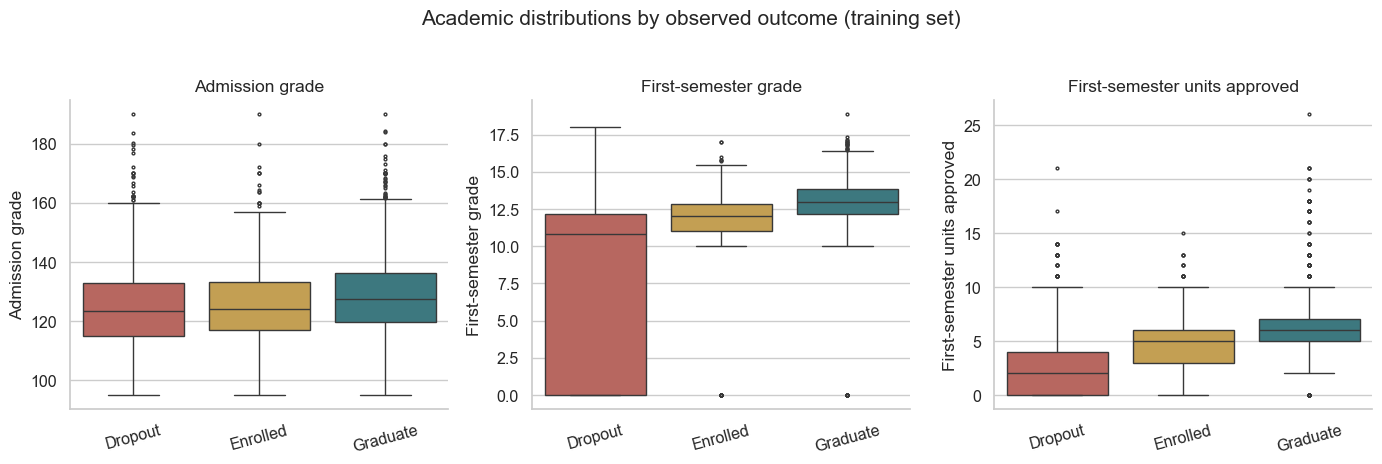

In [7]:
(fig, axes) = plt.subplots(1, 3, figsize=(14, 4.5))
ac = ['Admission grade', 'Curricular units 1st sem (grade)', 'Curricular units 1st sem (approved)']
labels = ['Admission grade', 'First-semester grade', 'First-semester units approved']
for (ax, c, label) in zip(axes, ac, labels):
    sns.boxplot(data=x, x='Target', y=c, order=ORDER, hue='Target', hue_order=ORDER, palette=COLORS, legend=False, ax=ax, fliersize=2)
    ax.set(xlabel='', ylabel=label, title=label)
    ax.tick_params(axis='x', rotation=15)
fig.suptitle('Academic distributions by observed outcome (training set)', y=1.03)
fig.tight_layout()
save('02_academic_by_outcome')
med = x.groupby('Target')[ac].median().reindex(ORDER)
med.to_csv(ROOT / 'tables/academic_medians.csv')


### 3.5 Financial indicators

Show within-group outcome percentages and descriptive 95% Wilson intervals. Financial timing is unverified.


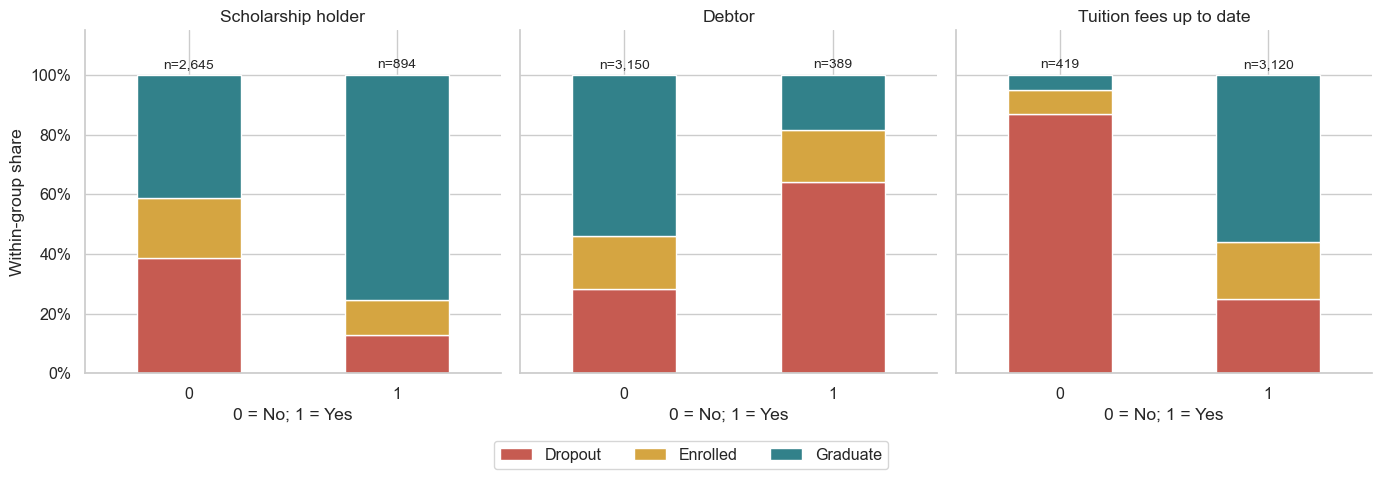

In [8]:
financial = []
(fig, axes) = plt.subplots(1, 3, figsize=(14, 4.5), sharey=True)
for (ax, c) in zip(axes, FIN):
    g = pd.crosstab(x[c], x.Target).reindex(columns=ORDER, fill_value=0)
    rates = g.div(g.sum(axis=1), axis=0)
    rates.plot.bar(stacked=True, color=COLORS, ax=ax, legend=False, rot=0)
    for (j, (v, row)) in enumerate(g.iterrows()):
        n = int(row.sum())
        k = int(row['Dropout'])
        p = k / n
        z = 1.96
        center = (p + z * z / (2 * n)) / (1 + z * z / n)
        half = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / (1 + z * z / n)
        financial.append({'feature': c, 'value': v, 'n': n, 'dropout_n': k, 'dropout_pct': round(100 * p, 2), 'wilson_low_pct': round(100 * (center - half), 2), 'wilson_high_pct': round(100 * (center + half), 2)})
        ax.text(j, 1.025, f'n={n:,}', ha='center', fontsize=10)
    ax.set(title=c, xlabel='0 = No; 1 = Yes', ylim=(0, 1.15))
    ax.yaxis.set_major_formatter(matplotlib.ticker.PercentFormatter(1))
axes[0].set_ylabel('Within-group share')
fig.legend(ORDER, loc='lower center', ncol=3, bbox_to_anchor=(0.5, -0.08))
fig.tight_layout()
save('03_financial_outcome_rates')
fin = pd.DataFrame(financial)
fin.to_csv(ROOT / 'tables/financial_dropout_rates.csv', index=False)


### 3.6 Age and academic progress

Inspect age and approval ratios; retain zero-enrollment observations explicitly.


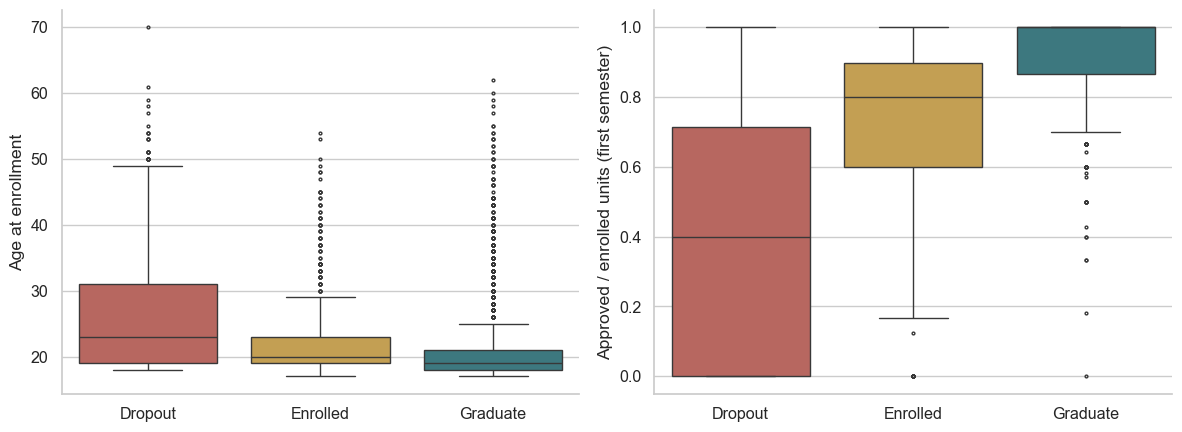

In [9]:
enrolled = x['Curricular units 1st sem (enrolled)']
x['First-semester approval rate'] = x['Curricular units 1st sem (approved)'].div(enrolled.where(enrolled > 0))
(fig, axes) = plt.subplots(1, 2, figsize=(12, 4.5))
for (ax, c, label) in zip(axes, ['Age at enrollment', 'First-semester approval rate'], ['Age at enrollment', 'Approved / enrolled units (first semester)']):
    sns.boxplot(data=x, x='Target', y=c, order=ORDER, hue='Target', hue_order=ORDER, palette=COLORS, legend=False, ax=ax, fliersize=2)
    ax.set(xlabel='', ylabel=label)
fig.tight_layout()
save('04_age_and_approval_rate')


### 3.7 Course context and numeric distributions

Export course summaries and inspect numeric shapes without removing valid extreme observations.


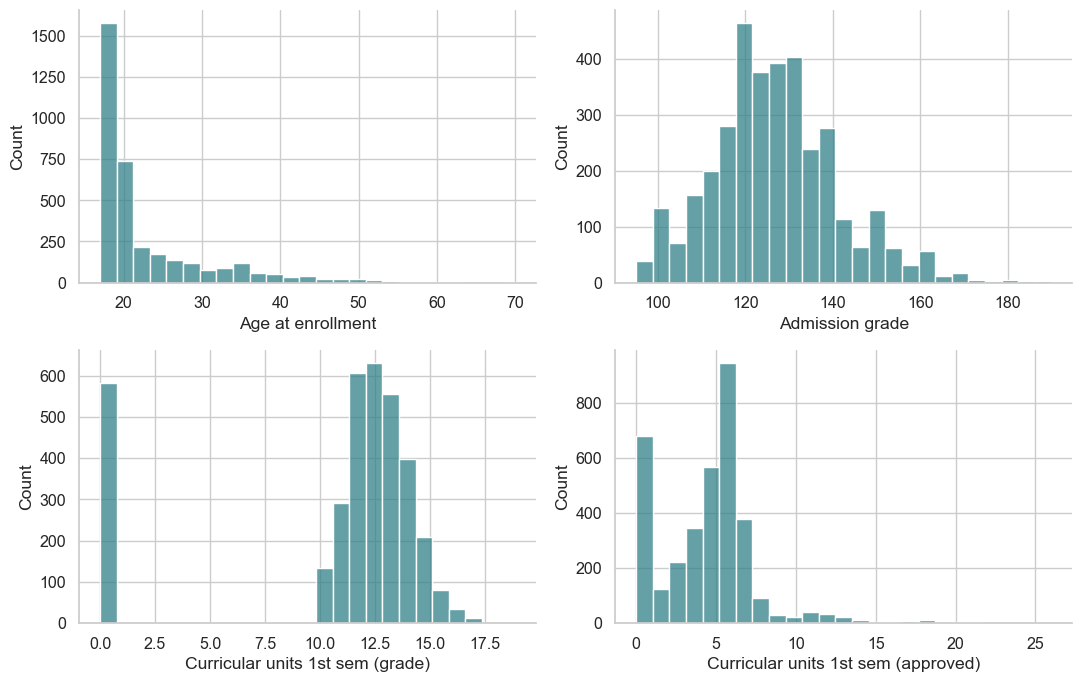

In [10]:
courses = x.groupby('Course').agg(n=('Target', 'size'), dropout_rate=('Target', lambda s: s.eq('Dropout').mean())).sort_values('n', ascending=False)
courses.to_csv(ROOT / 'tables/course_dropout_rates.csv')
hist = ['Age at enrollment', 'Admission grade', 'Curricular units 1st sem (grade)', 'Curricular units 1st sem (approved)']
(fig, axes) = plt.subplots(2, 2, figsize=(11, 7))
for (ax, c) in zip(axes.flat, hist):
    sns.histplot(data=x, x=c, bins=25, ax=ax, color=COLORS[2])
fig.tight_layout()
save('05_numeric_distributions')


### 3.8 Numeric correlations

Use Spearman correlations on numeric measurements; exclude nominal codes and target labels.


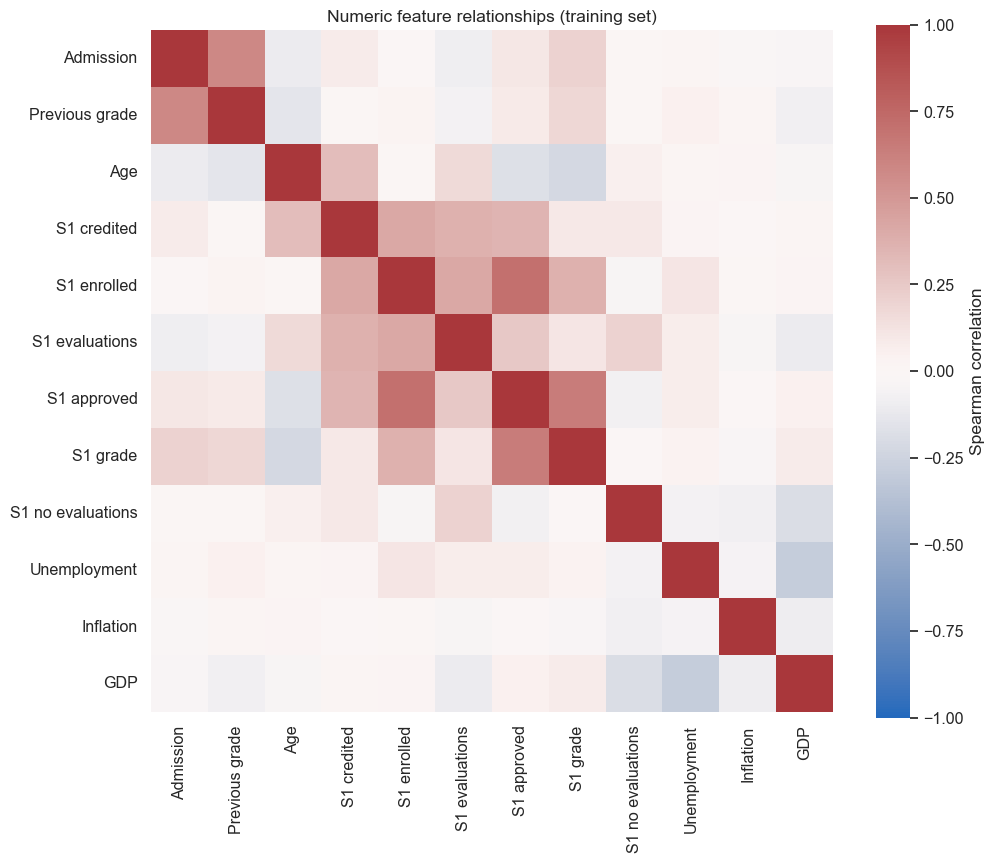

In [11]:
corrcols = ['Admission grade', 'Previous qualification (grade)', 'Age at enrollment', *first, 'Unemployment rate', 'Inflation rate', 'GDP']
corr = x[corrcols].corr(method='spearman')
corr.to_csv(ROOT / 'tables/spearman_correlations.csv')
short = ['Admission', 'Previous grade', 'Age', 'S1 credited', 'S1 enrolled', 'S1 evaluations', 'S1 approved', 'S1 grade', 'S1 no evaluations', 'Unemployment', 'Inflation', 'GDP']
(fig, ax) = plt.subplots(figsize=(11, 9))
sns.heatmap(corr, xticklabels=short, yticklabels=short, cmap='vlag', vmin=-1, vmax=1, center=0, ax=ax, square=True, cbar_kws={'label': 'Spearman correlation'})
ax.set_title('Numeric feature relationships (training set)')
save('06_numeric_correlations')
pairs = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool)).stack().rename('rho').reset_index()
pairs.columns = ['feature_1', 'feature_2', 'rho']
pairs['abs_rho'] = pairs.rho.abs()
pairs = pairs.sort_values('abs_rho', ascending=False)
pairs.to_csv(ROOT / 'tables/top_correlations.csv', index=False)


### 3.9 Export EDA metadata and summary

Record the input hash, shared split, tables, and a concise computed report.


In [12]:
metadata = {'source': SOURCE, 'data_sha256': hashlib.sha256(DATA_BYTES).hexdigest(), 'total_rows': len(d), 'train_n': len(x), 'test_n': len(te), 'seed': RANDOM_STATE, 'test_size': 0.2, 'row_id': 'zero-based original data row, excluding header', 'full_file_duplicate_rows': int(d.duplicated().sum()), 'training_missing_cells': int(x[eligible].isna().sum().sum()), 'second_semester_excluded': second}
(ROOT / 'tables/run_metadata.json').write_text(json.dumps(metadata, indent=2))
rate_lines = []
for c in FIN:
    f = fin[fin.feature.eq(c)].set_index('value')
    rate_lines.append(f"- **{c}:** dropout share is {f.loc[0, 'dropout_pct']:.1f}% for No (n={int(f.loc[0, 'n']):,}) and {f.loc[1, 'dropout_pct']:.1f}% for Yes (n={int(f.loc[1, 'n']):,}).")
report = '# Exploratory Data Analysis Report\n\n'
report += 'Training rows only. Associations do not establish causal effects.\n\n'
report += '## Outcome distribution\n' + md(ct) + '\n\n'
report += '## Academic medians\n' + md(med.round(2).reset_index()) + '\n\n'
report += '## Financial indicators\n' + '\n'.join(rate_lines) + '\n\n'
report += '## Top numeric correlations\n' + md(pairs.head(5).drop(columns='abs_rho').round(3))
report += '\n\nFinancial timestamps remain unverified. Enrolled outcomes remain unresolved. '
report += 'Temporal and external validation and independent final testing remain required.\n'
(ROOT / 'reports/partb_eda_report.md').write_text(report)
print(json.dumps(metadata, indent=2))
print('\nACADEMIC MEDIANS\n', med.to_string())
print('\nFINANCIAL RATES\n', fin.to_string(index=False))


{
  "source": "https://archive.ics.uci.edu/dataset/697/predict+students+dropout+and+academic+success",
  "data_sha256": "3ef126de5cefff26eb11fbb4237f1a1401cb64b488e2f1d598c23cedeb4c45ae",
  "total_rows": 4424,
  "train_n": 3539,
  "test_n": 885,
  "seed": 42,
  "test_size": 0.2,
  "row_id": "zero-based original data row, excluding header",
  "full_file_duplicate_rows": 0,
  "training_missing_cells": 0,
  "second_semester_excluded": [
    "Curricular units 2nd sem (credited)",
    "Curricular units 2nd sem (enrolled)",
    "Curricular units 2nd sem (evaluations)",
    "Curricular units 2nd sem (approved)",
    "Curricular units 2nd sem (grade)",
    "Curricular units 2nd sem (without evaluations)"
  ]
}

ACADEMIC MEDIANS
           Admission grade  Curricular units 1st sem (grade)  Curricular units 1st sem (approved)
Target                                                                                          
Dropout             123.3                         10.833333                

## 4. Preprocessing and feature engineering

Four original-column feature sets (18/24/21/27) exclude second-semester and macroeconomic fields. First-semester scenarios add two ratios and a zero-enrollment indicator. Learned imputation, encoding, and scaling remain inside each model pipeline. Financial availability dates remain unverified.


### 4.1 Identify semester variables

Identify first- and second-semester columns; future semester information is excluded from modeling.


In [13]:
# First-semester features
first_sem_cols = [
    col for col in df.columns
    if "1st sem" in col
]

# Second-semester features
second_sem_cols = [
    col for col in df.columns
    if "2nd sem" in col
]

print("First-semester features:", len(first_sem_cols))
print(first_sem_cols)

print("\nSecond-semester features:", len(second_sem_cols))
print(second_sem_cols)


First-semester features: 6
['Curricular units 1st sem (credited)', 'Curricular units 1st sem (enrolled)', 'Curricular units 1st sem (evaluations)', 'Curricular units 1st sem (approved)', 'Curricular units 1st sem (grade)', 'Curricular units 1st sem (without evaluations)']

Second-semester features: 6
['Curricular units 2nd sem (credited)', 'Curricular units 2nd sem (enrolled)', 'Curricular units 2nd sem (evaluations)', 'Curricular units 2nd sem (approved)', 'Curricular units 2nd sem (grade)', 'Curricular units 2nd sem (without evaluations)']


### 4.2 Define four feature sets

Keep original input columns separate from engineered variables and one-hot encoded dimensions.


In [14]:
# Conditional financial indicators
financial_cols = [
    "Scholarship holder",
    "Debtor",
    "Tuition fees up to date"
]

# Macroeconomic context variables
macro_cols = [
    "Unemployment rate",
    "Inflation rate",
    "GDP"
]

# Core admission features
# Financial timing is not yet verified.
admission_cols = [
    col for col in df.columns
    if col not in first_sem_cols
    + second_sem_cols
    + financial_cols
    + macro_cols
    + ["Target"]
]

# Admission + first-semester academic features
first_semester_cols = admission_cols + first_sem_cols

# Exploratory financial scenarios
admission_financial_cols = admission_cols + financial_cols

first_semester_financial_cols = (
    first_semester_cols + financial_cols
)

# Feature sets for modeling
feature_sets = {
    "Admission Only": admission_cols,
    "First Semester": first_semester_cols,
    "Admission + Financial": admission_financial_cols,
    "First Semester + Financial": first_semester_financial_cols
}

for name, cols in feature_sets.items():
    print(f"{name}: {len(cols)} features")

# Ensure no future information or target is included
for cols in feature_sets.values():
    assert "Target" not in cols
    assert not set(second_sem_cols).intersection(cols)
X_train_admission = X_train[admission_cols]
X_train_first_sem = X_train[first_semester_cols]


Admission Only: 18 features
First Semester: 24 features
Admission + Financial: 21 features
First Semester + Financial: 27 features


### 4.3 Define academic progress features

Keep zero denominators undefined for fold-local imputation and preserve a zero-enrollment indicator.


In [15]:
def add_first_semester_features(X):
    X = X.copy()

    enrolled = X["Curricular units 1st sem (enrolled)"]

    # Avoid division by zero
    denominator = enrolled.replace(0, np.nan)

    # Proportion of enrolled courses approved
    X["First semester pass rate"] = (
        X["Curricular units 1st sem (approved)"]
        / denominator
    )

    # Average evaluations per enrolled course
    X["Evaluations per enrolled course"] = (
        X["Curricular units 1st sem (evaluations)"]
        / denominator
    )

    # Preserve information about zero enrollment
    X["No first-semester enrollment"] = (
        enrolled == 0
    ).astype(int)

    return X


### 4.4 Inspect engineered examples

Preview the three derived variables using training records only.


In [16]:
sample = add_first_semester_features(
    X_train_first_sem.head(8)
)

display(sample[[
    "Curricular units 1st sem (enrolled)",
    "Curricular units 1st sem (approved)",
    "First semester pass rate",
    "Evaluations per enrolled course",
    "No first-semester enrollment"
]])


,Curricular units 1st sem (enrolled),Curricular units 1st sem (approved),First semester pass rate,Evaluations per enrolled course,No first-semester enrollment
2283,11,10,0.909091,1.272727,0
3874,5,0,0.000000,1.000000,0
2281,6,4,0.666667,2.166667,0
817,6,6,1.000000,1.000000,0
404,8,7,0.875000,1.000000,0
3126,6,6,1.000000,1.833333,0
959,5,0,0.000000,1.000000,0
4245,7,0,0.000000,1.285714,0


### 4.5 Identify categorical columns

Numerical category labels are encoded as categories rather than scaled as continuous measurements.


In [17]:
# Define Categorical Variables

categorical_features = [
    "Marital status",
    "Application mode",
    "Course",
    "Daytime/evening attendance",
    "Previous qualification",
    "Nacionality",
    "Mother's qualification",
    "Father's qualification",
    "Mother's occupation",
    "Father's occupation",
    "Displaced",
    "Educational special needs",
    "Debtor",
    "Tuition fees up to date",
    "Gender",
    "Scholarship holder",
    "International"
]


### 4.6 Build reusable preprocessing

Imputation, scaling, and encoding are fitted within each model training fold.


In [18]:
# Build Preprocessing Pipeline

def make_preprocessor(columns, add_engineered=False):

    columns = list(columns)

    if add_engineered:
        if not set(first_sem_cols).issubset(columns):
            raise ValueError(
                "First-semester features are required for engineering."
            )

    # Identify categorical and numerical features
    cat_cols = [
        col for col in columns
        if col in categorical_features
    ]

    num_cols = [
        col for col in columns
        if col not in categorical_features
    ]

    if add_engineered:
        num_cols += [
            "First semester pass rate",
            "Evaluations per enrolled course",
            "No first-semester enrollment"
        ]

    # Numerical preprocessing
    numeric_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])

    # Categorical preprocessing
    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ])

    # Combine transformations
    column_transformer = ColumnTransformer([
        ("numeric", numeric_pipeline, num_cols),
        ("categorical", categorical_pipeline, cat_cols)
    ])

    # Include feature engineering inside the pipeline
    if add_engineered:
        preprocessor = Pipeline([
            (
                "feature_engineering",
                FunctionTransformer(
                    add_first_semester_features,
                    validate=False
                )
            ),
            ("preprocessing", column_transformer)
        ])
    else:
        preprocessor = Pipeline([
            ("preprocessing", column_transformer)
        ])

    return preprocessor


### 4.7 Create scenario pipelines

Reuse the same preprocessing definition for all four scenarios.


In [19]:
# Create preprocessing pipelines for all feature sets
preprocessors = {}

for name, cols in feature_sets.items():

    use_first_sem = "First Semester" in name

    preprocessors[name] = make_preprocessor(
        cols,
        add_engineered=use_first_sem
    )

# Keep original variable names for compatibility
admission_preprocessor = preprocessors["Admission Only"]

first_semester_preprocessor = preprocessors["First Semester"]

print("All preprocessing pipelines created successfully!")


All preprocessing pipelines created successfully!


### 4.8 Check classifier integration

Fit a training-only smoke model to check pipeline compatibility.


In [20]:
# Test whether the preprocessing pipeline works with a classifier

from sklearn.base import clone
smoke_model = Pipeline([
    ("preprocessing", clone(first_semester_preprocessor)),
    ("model", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

# Fit using training data only
smoke_model.fit(X_train_first_sem, y_train)

print("Pipeline fitted successfully")

# Check transformed training data shape
X_train_transformed = smoke_model.named_steps[
    "preprocessing"
].transform(X_train_first_sem)

print("Transformed shape:", X_train_transformed.shape)


Pipeline fitted successfully
Transformed shape: (3539, 232)


### 4.9 Check split and transformed values

Verify separation of training and test rows and finite transformed values.


In [21]:
# Check that selected feature groups contain expected columns
assert set(admission_cols).issubset(first_semester_cols)

# Check that training and test sets are separate
assert X_train.index.intersection(X_test.index).empty

# Check that no infinite values appear after preprocessing
from scipy import sparse

# Use the fitted preprocessor from the smoke-test model
transformed = smoke_model.named_steps[
    "preprocessing"
].transform(X_train_first_sem)

values = (
    transformed.data
    if sparse.issparse(transformed)
    else transformed
)

assert np.isfinite(values).all()

print("All preprocessing checks passed!")


All preprocessing checks passed!


### 4.10 Check feature exclusions

Confirm that neither the target nor second-semester variables enters any modeled scenario.


In [22]:
# Check that target is excluded
assert "Target" not in admission_cols
assert "Target" not in first_semester_cols

# Check that second-semester information is excluded
assert not set(second_sem_cols).intersection(admission_cols)
assert not set(second_sem_cols).intersection(first_semester_cols)

# Check feature groups
print("Admission-only features:", len(admission_cols))
print("First-semester features:", len(first_semester_cols))

# Check input dimensions
print("Admission training data:", X_train_admission.shape)
print("First-semester training data:", X_train_first_sem.shape)

print("\nAll passed")


Admission-only features: 18
First-semester features: 24
Admission training data: (3539, 18)
First-semester training data: (3539, 24)

All passed


### 4.11 Validate every scenario

Check each scenario with an independent clone of the shared preprocessing pipeline.


In [23]:
from sklearn.base import clone

# Check all feature sets and pipelines
for name, cols in feature_sets.items():

    X_subset = X_train[cols]

    # Use an independent copy of the pipeline
    pipeline = clone(preprocessors[name])

    # Fit preprocessing on training data only
    transformed = pipeline.fit_transform(X_subset)

    # Check the transformed values
    from scipy import sparse

    values = (
        transformed.data
        if sparse.issparse(transformed)
        else transformed
    )

    assert np.isfinite(values).all()

    print(
        f"{name}: {X_subset.shape[1]} original features, "
        f"{transformed.shape[1]} transformed features"
    )

print("\nAll preprocessing integration checks passed!")


Admission Only: 18 original features, 223 transformed features
First Semester: 24 original features, 232 transformed features
Admission + Financial: 21 original features, 229 transformed features
First Semester + Financial: 27 original features, 238 transformed features

All preprocessing integration checks passed!


## 5. Baselines and initial five-model comparison

Scores use five stratified training-data folds. In-sample training scores are retained to assess overfitting. The majority baseline and model comparison share the same folds.


### 5.1 Majority-class benchmark

Define class labels and metrics, then evaluate the simplest benchmark on training folds.


In [24]:
RANDOM_STATE = 42
cv = CV
label_encoder = LabelEncoder()
y_train_encoded = label_encoder.fit_transform(y_train)
class_names = label_encoder.classes_
dropout_class = int(label_encoder.transform(['Dropout'])[0])
scoring = {'accuracy': 'accuracy', 'f1_macro': 'f1_macro', 'balanced_accuracy': 'balanced_accuracy', 'dropout_recall': make_scorer(recall_score, labels=[dropout_class], average='macro', zero_division=0), 'dropout_precision': make_scorer(precision_score, labels=[dropout_class], average='macro', zero_division=0)}
baseline_cv = cross_validate(DummyClassifier(strategy='most_frequent'), X_train[feature_sets['Admission Only']], y_train_encoded, cv=cv, scoring=scoring, n_jobs=2)
baseline_results = {metric: {'mean': float(np.mean(baseline_cv[f'test_{metric}'])), 'std': float(np.std(baseline_cv[f'test_{metric}']))} for metric in scoring}
baseline_table = pd.DataFrame(baseline_results).T
baseline_table.columns = ['CV Mean', 'CV Std']
display(baseline_table.round(4))


,CV Mean,CV Std
accuracy,0.4993,0.0006
f1_macro,0.2220,0.0002
balanced_accuracy,0.3333,0.0000
dropout_recall,0.0000,0.0000
dropout_precision,0.0000,0.0000


### 5.2 Compare five classifiers

Evaluate the same five algorithms under identical folds and preprocessing conditions.


In [25]:
models = {'Logistic Regression': LogisticRegression(max_iter=2000, random_state=RANDOM_STATE), 'Decision Tree': DecisionTreeClassifier(random_state=RANDOM_STATE), 'Random Forest': RandomForestClassifier(n_estimators=150, random_state=RANDOM_STATE, n_jobs=1), 'Gradient Boosting': GradientBoostingClassifier(random_state=RANDOM_STATE), 'XGBoost': XGBClassifier(n_estimators=150, random_state=RANDOM_STATE, n_jobs=1, tree_method='hist', eval_metric='mlogloss')}
comparison_rows = []
for (feature_set_name, selected_columns) in feature_sets.items():
    X_selected = X_train[selected_columns]
    for (model_name, estimator) in models.items():
        pipeline = Pipeline([('preprocessing', clone(preprocessors[feature_set_name])), ('model', clone(estimator))])
        scores = cross_validate(pipeline, X_selected, y_train_encoded, cv=cv, scoring=scoring, return_train_score=True, n_jobs=2, error_score='raise')
        row = {'Feature Set': feature_set_name, 'Model': model_name, 'Number of Features': len(selected_columns)}
        for metric in scoring:
            row[f'CV {metric} Mean'] = float(np.mean(scores[f'test_{metric}']))
            row[f'CV {metric} Std'] = float(np.std(scores[f'test_{metric}']))
        row['Train F1 Macro Mean'] = float(np.mean(scores['train_f1_macro']))
        row['F1 Generalization Gap'] = row['Train F1 Macro Mean'] - row['CV f1_macro Mean']
        row['CV Fit Time Mean'] = float(np.mean(scores['fit_time']))
        comparison_rows.append(row)
        print(f"{feature_set_name} | {model_name} | F1 macro: {row['CV f1_macro Mean']:.4f} ± {row['CV f1_macro Std']:.4f} | Dropout recall: {row['CV dropout_recall Mean']:.4f}")
comparison_results = pd.DataFrame(comparison_rows).sort_values(['Feature Set', 'CV f1_macro Mean', 'CV dropout_recall Mean'], ascending=[True, False, False]).reset_index(drop=True)
display(comparison_results.round(4))


Admission Only | Logistic Regression | F1 macro: 0.4924 ± 0.0182 | Dropout recall: 0.5294
Admission Only | Decision Tree | F1 macro: 0.4241 ± 0.0205 | Dropout recall: 0.4484
Admission Only | Random Forest | F1 macro: 0.4516 ± 0.0225 | Dropout recall: 0.5285
Admission Only | Gradient Boosting | F1 macro: 0.4803 ± 0.0172 | Dropout recall: 0.5171
Admission Only | XGBoost | F1 macro: 0.4776 ± 0.0200 | Dropout recall: 0.4986
First Semester | Logistic Regression | F1 macro: 0.6206 ± 0.0099 | Dropout recall: 0.6966
First Semester | Decision Tree | F1 macro: 0.5534 ± 0.0060 | Dropout recall: 0.6280
First Semester | Random Forest | F1 macro: 0.6153 ± 0.0106 | Dropout recall: 0.7185
First Semester | Gradient Boosting | F1 macro: 0.6291 ± 0.0228 | Dropout recall: 0.7124
First Semester | XGBoost | F1 macro: 0.6320 ± 0.0149 | Dropout recall: 0.6939
Admission + Financial | Logistic Regression | F1 macro: 0.5461 ± 0.0107 | Dropout recall: 0.5971
Admission + Financial | Decision Tree | F1 macro: 0.475

,Feature Set,Model,Number of Features,CV accuracy Mean,CV accuracy Std,CV f1_macro Mean,CV f1_macro Std,CV balanced_accuracy Mean,CV balanced_accuracy Std,CV dropout_recall Mean,CV dropout_recall Std,CV dropout_precision Mean,CV dropout_precision Std,Train F1 Macro Mean,F1 Generalization Gap,CV Fit Time Mean
0,Admission + Financial,Logistic Regression,21,0.6476,0.0143,0.5461,0.0107,0.5443,0.0111,0.5971,0.0390,0.6620,0.0201,0.6032,0.0571,0.1550
1,Admission + Financial,XGBoost,21,0.6284,0.0113,0.5380,0.0148,0.5361,0.0142,0.5821,0.0567,0.6302,0.0108,0.9830,0.4449,0.3610
2,Admission + Financial,Gradient Boosting,21,0.6493,0.0099,0.5307,0.0101,0.5341,0.0083,0.5839,0.0523,0.6730,0.0148,0.6406,0.1099,1.2505
3,Admission + Financial,Random Forest,21,0.6383,0.0063,0.5063,0.0113,0.5191,0.0068,0.6068,0.0363,0.6427,0.0161,1.0000,0.4937,1.1003
4,Admission + Financial,Decision Tree,21,0.5343,0.0110,0.4755,0.0143,0.4763,0.0137,0.5339,0.0209,0.5167,0.0222,1.0000,0.5245,0.0718
5,Admission Only,Logistic Regression,18,0.5993,0.0167,0.4924,0.0182,0.4950,0.0168,0.5294,0.0393,0.5767,0.0210,0.5534,0.0610,0.1523
6,Admission Only,Gradient Boosting,18,0.6019,0.0101,0.4803,0.0172,0.4881,0.0114,0.5171,0.0266,0.5731,0.0154,0.5966,0.1163,1.1282
7,Admission Only,XGBoost,18,0.5657,0.0167,0.4776,0.0200,0.4776,0.0175,0.4986,0.0451,0.5208,0.0297,0.9770,0.4994,0.3068
8,Admission Only,Random Forest,18,0.5843,0.0146,0.4516,0.0225,0.4684,0.0166,0.5285,0.0372,0.5489,0.0237,1.0000,0.5484,1.1211
9,Admission Only,Decision Tree,18,0.4840,0.0223,0.4241,0.0205,0.4245,0.0208,0.4484,0.0509,0.4462,0.0275,1.0000,0.5759,0.0680


### 5.3 Export comparison and plot macro F1

Save the complete model comparison and compare admission versus first-semester macro F1.


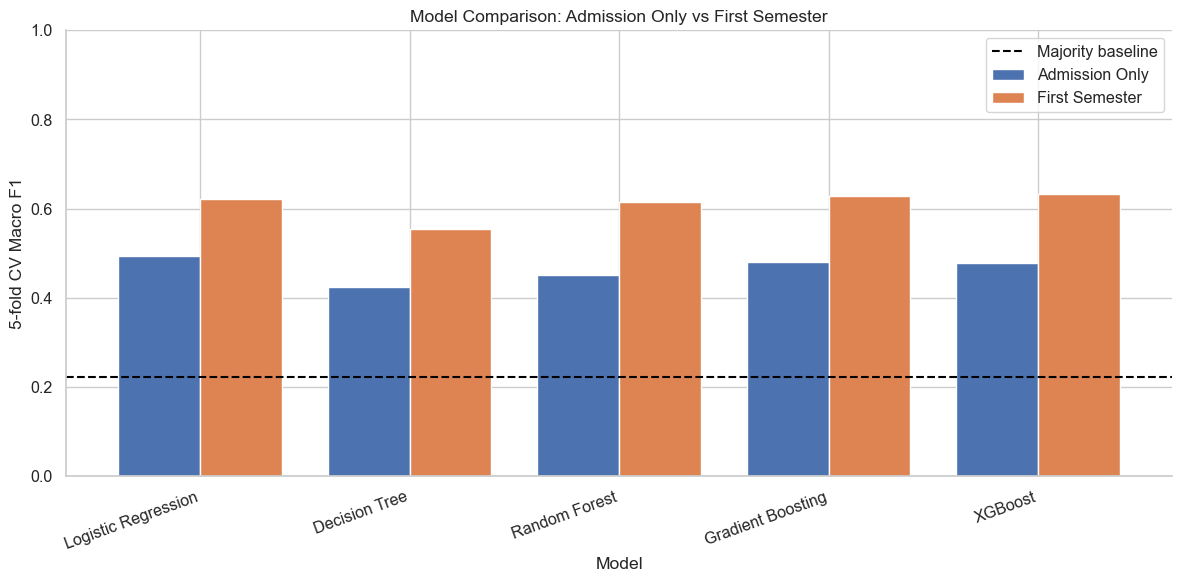

In [27]:
results_dir = RESULTS_ROOT / "part_d_results"
results_dir.mkdir(parents=True, exist_ok=True)
comparison_results.to_csv(results_dir / "model_cv_comparison.csv", index=False)
baseline_table.to_csv(results_dir / "majority_class_baseline.csv")

primary_sets = ["Admission Only", "First Semester"]
metric_plot = comparison_results[comparison_results["Feature Set"].isin(primary_sets)].pivot(
    index="Model", columns="Feature Set", values="CV f1_macro Mean"
).reindex(index=list(models), columns=primary_sets)

ax = metric_plot.plot(kind="bar", figsize=(12, 6), width=0.78)
ax.axhline(baseline_results["f1_macro"]["mean"], color="black", linestyle="--", label="Majority baseline")
ax.set_ylabel("5-fold CV Macro F1")
ax.set_xlabel("Model")
ax.set_title("Model Comparison: Admission Only vs First Semester")
ax.set_ylim(0, 1)
ax.legend()
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.savefig(results_dir / "model_comparison_macro_f1.png", dpi=200, bbox_inches="tight")
plt.show()


### 5.4 Dropout recall and scenario improvements

Compare dropout detection and calculate feature-set improvements for each estimator.


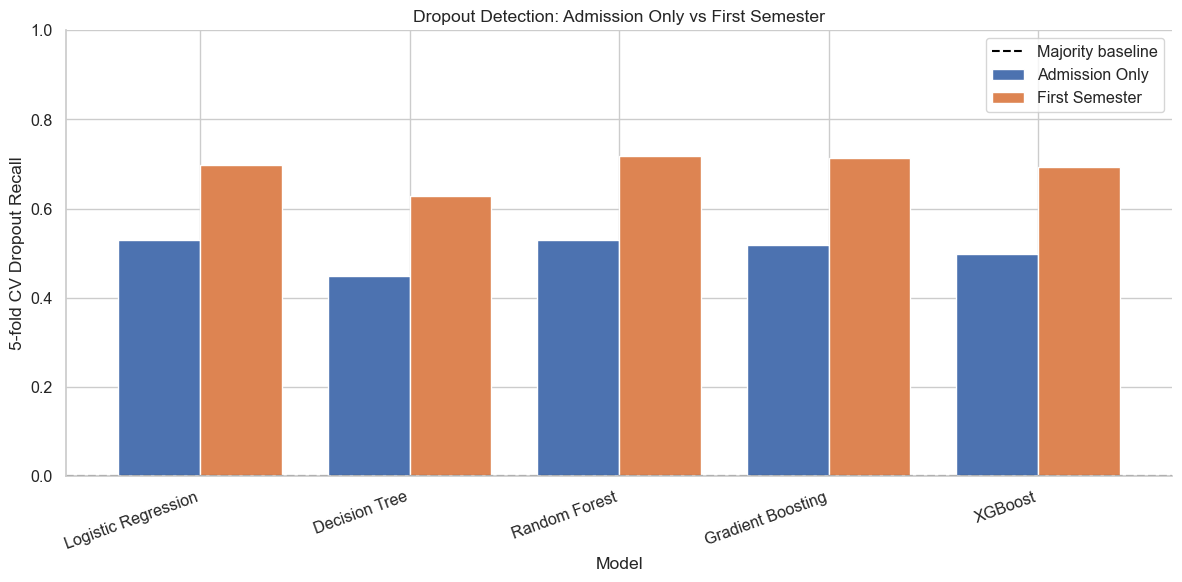

,First Semester - Admission Only,Admission + Financial - Admission Only,First Semester + Financial - First Semester
Model,,,
Random Forest,0.1637,0.0546,0.0330
XGBoost,0.1545,0.0605,0.0316
Gradient Boosting,0.1488,0.0504,0.0324
Decision Tree,0.1293,0.0514,0.0249
Logistic Regression,0.1282,0.0537,0.0463


In [28]:
recall_plot = comparison_results[comparison_results['Feature Set'].isin(primary_sets)].pivot(index='Model', columns='Feature Set', values='CV dropout_recall Mean').reindex(index=list(models), columns=primary_sets)
ax = recall_plot.plot(kind='bar', figsize=(12, 6), width=0.78)
ax.axhline(baseline_results['dropout_recall']['mean'], color='black', linestyle='--', label='Majority baseline')
ax.set_ylabel('5-fold CV Dropout Recall')
ax.set_xlabel('Model')
ax.set_title('Dropout Detection: Admission Only vs First Semester')
ax.set_ylim(0, 1)
ax.legend()
plt.xticks(rotation=20, ha='right')
plt.tight_layout()
plt.savefig(results_dir / 'model_comparison_dropout_recall.png', dpi=200, bbox_inches='tight')
plt.show()
f1_scenarios = comparison_results.pivot(index='Model', columns='Feature Set', values='CV f1_macro Mean')
scenario_improvement = pd.DataFrame({'First Semester - Admission Only': f1_scenarios['First Semester'] - f1_scenarios['Admission Only'], 'Admission + Financial - Admission Only': f1_scenarios['Admission + Financial'] - f1_scenarios['Admission Only'], 'First Semester + Financial - First Semester': f1_scenarios['First Semester + Financial'] - f1_scenarios['First Semester']}).sort_values('First Semester - Admission Only', ascending=False)
scenario_improvement.to_csv(results_dir / 'feature_set_improvements.csv')
display(scenario_improvement.round(4))


### Shortlist and preliminary out-of-fold error analysis

The shortlist is ranked by first-semester macro F1. The following confusion matrix belongs to the best initial untuned model, not the later selected ensemble. All predictions are out of fold on training rows.


### 5.5 Shortlist three models

Rank first-semester candidates by macro F1 and retain the top three.


In [29]:
selection_feature_set = "First Semester"
shortlist_table = comparison_results[comparison_results["Feature Set"] == selection_feature_set].sort_values(
    ["CV f1_macro Mean", "CV dropout_recall Mean", "CV f1_macro Std"],
    ascending=[False, False, True]
).head(3).reset_index(drop=True)

shortlisted_models = shortlist_table["Model"].tolist()
shortlisted_pipelines = {
    name: Pipeline([
        ("preprocessing", clone(preprocessors[selection_feature_set])),
        ("model", clone(models[name]))
    ])
    for name in shortlisted_models
}

shortlist_table.to_csv(results_dir / "top_three_models.csv", index=False)
display(shortlist_table.round(4))

trained_shortlist = {
    name: clone(pipeline).fit(X_train[feature_sets[selection_feature_set]], y_train_encoded)
    for name, pipeline in shortlisted_pipelines.items()
}
print("Shortlisted models:", shortlisted_models)


,Feature Set,Model,Number of Features,CV accuracy Mean,CV accuracy Std,CV f1_macro Mean,CV f1_macro Std,CV balanced_accuracy Mean,CV balanced_accuracy Std,CV dropout_recall Mean,CV dropout_recall Std,CV dropout_precision Mean,CV dropout_precision Std,Train F1 Macro Mean,F1 Generalization Gap,CV Fit Time Mean
0,First Semester,XGBoost,24,0.7149,0.0195,0.6320,0.0149,0.6266,0.0134,0.6939,0.0238,0.7352,0.0201,0.9994,0.3673,0.4335
1,First Semester,Gradient Boosting,24,0.7251,0.0158,0.6291,0.0228,0.6249,0.0189,0.7124,0.0274,0.7427,0.0294,0.7310,0.1020,1.9181
2,First Semester,Logistic Regression,24,0.7152,0.0049,0.6206,0.0099,0.6164,0.0065,0.6966,0.0213,0.7143,0.0157,0.6793,0.0587,0.1800


Shortlisted models: ['XGBoost', 'Gradient Boosting', 'Logistic Regression']


### 5.6 Generate out-of-fold class metrics

Each training record is predicted by a model that did not train on that record.


In [30]:
oof_predictions = {}
oof_metrics = []

def oof_report(model_name, predictions):
    report = classification_report(
        y_train_encoded,
        predictions,
        labels=np.arange(len(class_names)),
        target_names=class_names,
        output_dict=True,
        zero_division=0
    )
    for class_name in class_names:
        oof_metrics.append({
            "Model": model_name,
            "Class": class_name,
            "Precision": report[class_name]["precision"],
            "Recall": report[class_name]["recall"],
            "F1": report[class_name]["f1-score"],
            "Support": int(report[class_name]["support"])
        })

for model_name, pipeline in shortlisted_pipelines.items():
    predictions = cross_val_predict(
        pipeline,
        X_train[feature_sets[selection_feature_set]],
        y_train_encoded,
        cv=cv,
        n_jobs=2
    )
    oof_predictions[model_name] = predictions
    oof_report(model_name, predictions)

cv_class_performance = pd.DataFrame(oof_metrics)
cv_class_performance.to_csv(results_dir / "shortlist_oof_class_performance.csv", index=False)
display(cv_class_performance.round(4))


,Model,Class,Precision,Recall,F1,Support
0,XGBoost,Dropout,0.7353,0.6939,0.7140,1137
1,XGBoost,Enrolled,0.4442,0.3134,0.3675,635
2,XGBoost,Graduate,0.7641,0.8727,0.8148,1767
3,Gradient Boosting,Dropout,0.7424,0.7124,0.7271,1137
4,Gradient Boosting,Enrolled,0.4718,0.2630,0.3377,635
5,Gradient Boosting,Graduate,0.7588,0.8993,0.8231,1767
6,Logistic Regression,Dropout,0.7142,0.6966,0.7053,1137
7,Logistic Regression,Enrolled,0.4855,0.2630,0.3412,635
8,Logistic Regression,Graduate,0.7536,0.8896,0.8160,1767


### 5.7 Preliminary confusion matrices

Display the initial shortlisted winner; these are training out-of-fold results, not final ensemble test results.


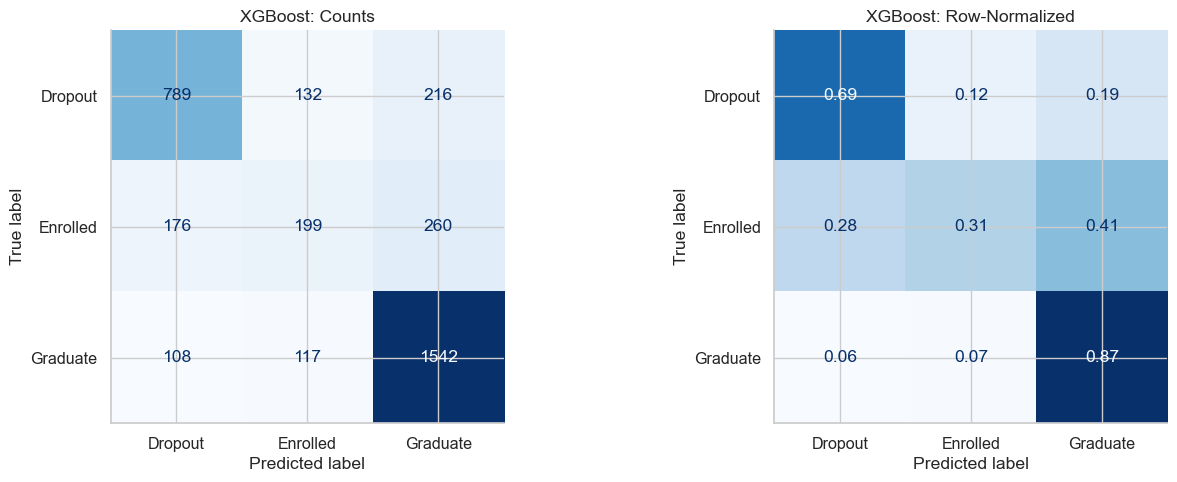

In [31]:
best_model_name = shortlisted_models[0]
best_oof_predictions = oof_predictions[best_model_name]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, normalization, title, value_format in [
    (axes[0], None, "Counts", "d"),
    (axes[1], "true", "Row-Normalized", ".2f")
]:
    cm = confusion_matrix(
        y_train_encoded,
        best_oof_predictions,
        labels=np.arange(len(class_names)),
        normalize=normalization
    )
    ConfusionMatrixDisplay(cm, display_labels=class_names).plot(
        ax=ax, cmap="Blues", colorbar=False, values_format=value_format
    )
    ax.set_title(f"{best_model_name}: {title}")

plt.tight_layout()
plt.savefig(results_dir / "best_model_cv_confusion_matrices.png", dpi=200, bbox_inches="tight")
plt.show()


### 5.8 Summarize error types

Count actual-versus-predicted misclassifications to support preliminary error analysis.


In [32]:
error_table = pd.DataFrame({
    "Actual": label_encoder.inverse_transform(y_train_encoded),
    "Predicted": label_encoder.inverse_transform(best_oof_predictions)
})

error_counts = (
    error_table.loc[error_table["Actual"] != error_table["Predicted"]]
    .groupby(["Actual", "Predicted"])
    .size()
    .reset_index(name="Count")
    .sort_values("Count", ascending=False)
    .reset_index(drop=True)
)
error_counts["Share of All Errors"] = error_counts["Count"] / error_counts["Count"].sum()
error_counts.to_csv(results_dir / "best_model_cv_error_types.csv", index=False)
display(error_counts.round(4))


,Actual,Predicted,Count,Share of All Errors
0,Enrolled,Graduate,260,0.2577
1,Dropout,Graduate,216,0.2141
2,Enrolled,Dropout,176,0.1744
3,Dropout,Enrolled,132,0.1308
4,Graduate,Enrolled,117,0.1160
5,Graduate,Dropout,108,0.1070


## 6. Tune the shortlisted models

Randomized search reuses the training CV folds (10 trials each for boosting models and 8 for Logistic Regression in full mode). This is not nested CV; reported selection metrics can be optimistic.


In [33]:
PRIMARY_SET = selection_feature_set
X_primary = X_train[feature_sets[PRIMARY_SET]]
dropout_code = dropout_class
assert set(shortlisted_models) == {'XGBoost', 'Gradient Boosting', 'Logistic Regression'}


### 6.1 Search spaces

Define complexity, regularization, learning-rate, and class-weight search ranges.


In [34]:
models = {
    'XGBoost': XGBClassifier(n_estimators=150, random_state=RANDOM_STATE,
                             n_jobs=1, tree_method='hist', eval_metric='mlogloss'),
    'Gradient Boosting': GradientBoostingClassifier(random_state=RANDOM_STATE),
    'Logistic Regression': LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)
}
parameter_distributions = {
    'XGBoost': {
        'model__n_estimators': randint(80, 261),
        'model__max_depth': randint(2, 6),
        'model__learning_rate': loguniform(0.02, 0.20),
        'model__subsample': uniform(0.65, 0.35),
        'model__colsample_bytree': uniform(0.65, 0.35),
        'model__min_child_weight': randint(1, 9),
        'model__reg_lambda': loguniform(0.3, 30.0),
    },
    'Gradient Boosting': {
        'model__n_estimators': randint(80, 261),
        'model__max_depth': randint(1, 4),
        'model__learning_rate': loguniform(0.02, 0.20),
        'model__subsample': uniform(0.65, 0.35),
        'model__min_samples_leaf': randint(1, 16),
    },
    'Logistic Regression': {
        'model__C': loguniform(0.03, 30.0),
        'model__class_weight': [None, 'balanced'],
    },
}


### 6.2 Run randomized searches

Fit all candidates using training CV and export every search trial.


In [35]:
searches = {}
search_rows = []
for model_name, estimator in models.items():
    pipe = Pipeline([('preprocessing', clone(preprocessors[PRIMARY_SET])),
                     ('model', clone(estimator))])
    search = RandomizedSearchCV(
        estimator=pipe, param_distributions=parameter_distributions[model_name],
        n_iter=ITERATIONS[model_name], cv=CV, scoring='f1_macro', refit=True,
        n_jobs=1, random_state=RANDOM_STATE, error_score='raise',
        return_train_score=True
    )
    print(f'Tuning {model_name} ({ITERATIONS[model_name]} samples x {N_SPLITS} folds) ...')
    search.fit(X_primary, y_train_encoded)
    searches[model_name] = search
    idx = search.best_index_
    search_rows.append({
        'Model': model_name,
        'CV Macro F1 Mean': float(search.cv_results_['mean_test_score'][idx]),
        'CV Macro F1 Std': float(search.cv_results_['std_test_score'][idx]),
        'Train Macro F1 Mean': float(search.cv_results_['mean_train_score'][idx]),
        'Train - CV Gap': float(search.cv_results_['mean_train_score'][idx] -
                               search.cv_results_['mean_test_score'][idx]),
        'Best Params': json.dumps(search.best_params_, sort_keys=True)
    })
    pd.DataFrame(search.cv_results_).to_csv(
        OUTPUT_DIR / f'search_trials_{model_name.lower().replace(" ", "_")}.csv', index=False)


Tuning XGBoost (10 samples x 5 folds) ...
Tuning Gradient Boosting (10 samples x 5 folds) ...
Tuning Logistic Regression (8 samples x 5 folds) ...


### 6.3 Compare tuned candidates

Report validation macro F1, fold variation, and training–validation gaps.


In [37]:
tuning_results = pd.DataFrame(search_rows).sort_values(
    'CV Macro F1 Mean', ascending=False).reset_index(drop=True)
tuning_results.to_csv(OUTPUT_DIR / 'tuning_comparison.csv', index=False)
display(tuning_results[['Model', 'CV Macro F1 Mean', 'CV Macro F1 Std',
                        'Train - CV Gap']].round(4))


,Model,CV Macro F1 Mean,CV Macro F1 Std,Train - CV Gap
0,Logistic Regression,0.6476,0.0158,0.0292
1,XGBoost,0.6386,0.0077,0.1616
2,Gradient Boosting,0.6341,0.0134,0.1458


## 7. Tuned candidates and equal-weight soft voting

Each voting member contains its own full preprocessing pipeline. No final test predictions are generated.


### 7.1 Shared candidate scoring

Summarize the same validation metrics for each tuned model and the ensemble.


In [38]:
def summarize_cv(name, estimator, features, labels):
    result = cross_validate(estimator, features, labels, cv=CV, scoring=scoring,
                            n_jobs=1, error_score='raise')
    return {
        'Candidate': name,
        'Macro F1 Mean': float(np.mean(result['test_f1_macro'])),
        'Macro F1 Std': float(np.std(result['test_f1_macro'])),
        'Dropout Recall Mean': float(np.mean(result['test_dropout_recall'])),
        'Dropout Recall Std': float(np.std(result['test_dropout_recall'])),
        'Accuracy Mean': float(np.mean(result['test_accuracy'])),
    }


### 7.2 Build and compare soft voting

Average tuned members’ probabilities with equal weights; select by training-CV macro F1.


In [39]:
tuned_pipelines = {name: clone(search.best_estimator_) for (name, search) in searches.items()}
soft_vote = VotingClassifier(estimators=[('xgb', clone(tuned_pipelines['XGBoost'])), ('gb', clone(tuned_pipelines['Gradient Boosting'])), ('lr', clone(tuned_pipelines['Logistic Regression']))], voting='soft', n_jobs=1)
candidate_rows = [summarize_cv(n, model, X_primary, y_train_encoded) for (n, model) in tuned_pipelines.items()]
candidate_rows.append(summarize_cv('Soft Voting Ensemble', soft_vote, X_primary, y_train_encoded))
candidate_results = pd.DataFrame(candidate_rows).sort_values(['Macro F1 Mean', 'Dropout Recall Mean'], ascending=False).reset_index(drop=True)
candidate_results.to_csv(OUTPUT_DIR / 'candidate_ensemble_cv.csv', index=False)
display(candidate_results.round(4))
WINNER_NAME = str(candidate_results.iloc[0]['Candidate'])
WINNER_PIPELINE = soft_vote if WINNER_NAME == 'Soft Voting Ensemble' else tuned_pipelines[WINNER_NAME]
print('Provisional CV winner; independent evaluation remains required:', WINNER_NAME)


,Candidate,Macro F1 Mean,Macro F1 Std,Dropout Recall Mean,Dropout Recall Std,Accuracy Mean
0,Soft Voting Ensemble,0.6505,0.0153,0.6965,0.0316,0.7287
1,Logistic Regression,0.6476,0.0158,0.6429,0.0221,0.6948
2,XGBoost,0.6386,0.0077,0.7053,0.0278,0.7287
3,Gradient Boosting,0.6341,0.0134,0.7045,0.0192,0.7256


Provisional CV winner; independent evaluation remains required: Soft Voting Ensemble


### 7.3 Plot tuned candidate performance

Display means and fold standard deviations; these are selection results, not independent test scores.


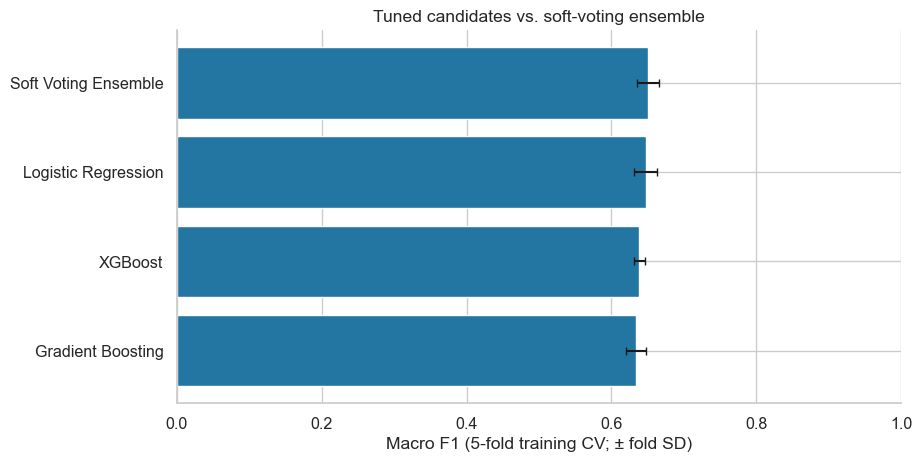

In [40]:
plt.figure(figsize=(9.4, 4.8))
plot = candidate_results.sort_values('Macro F1 Mean')
plt.barh(plot['Candidate'], plot['Macro F1 Mean'], xerr=plot['Macro F1 Std'], capsize=3, color='#2476a2')
plt.xlabel('Macro F1 (5-fold training CV; ± fold SD)')
plt.title('Tuned candidates vs. soft-voting ensemble')
plt.xlim(0, 1)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / '01_tuning_and_ensemble.png', dpi=180, bbox_inches='tight')
plt.show()


## 8. Fixed-model academic and financial feature comparison

This reruns untuned Logistic Regression under identical conditions across feature sets. Historical saved outputs differ slightly for Admission + Financial (initial comparison 0.5461 versus later ablation 0.5464). Both calculations are retained below and their new-run difference is exported; no historical result is silently substituted.


### 8.1 Controlled feature-set comparison

Keep Logistic Regression settings and folds fixed across the four feature sets.


In [41]:
ablation_model = LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)
ablation_rows = []
for set_name, cols in feature_sets.items():
    pipeline = Pipeline([('preprocessing', clone(preprocessors[set_name])),
                         ('model', clone(ablation_model))])
    row = summarize_cv(set_name, pipeline, X_train[cols], y_train_encoded)
    ablation_rows.append({'Feature Set': set_name, 'Raw Feature Count': len(cols),
                          **{k: v for k, v in row.items() if k != 'Candidate'}})
ablation_results = pd.DataFrame(ablation_rows).set_index('Feature Set').reindex(
    list(feature_sets)).reset_index()
ablation_results.to_csv(OUTPUT_DIR / 'academic_financial_ablation.csv', index=False)
display(ablation_results.round(4))

f1_by_set = ablation_results.set_index('Feature Set')['Macro F1 Mean']
academic_gain = f1_by_set['First Semester'] - f1_by_set['Admission Only']
financial_gain_admission = f1_by_set['Admission + Financial'] - f1_by_set['Admission Only']
financial_gain_semester = (f1_by_set['First Semester + Financial'] -
                           f1_by_set['First Semester'])
print(f'Additional first-semester academic measurements: Δ Macro F1 = {academic_gain:+.4f}')
print(f'Financial indicators at admission (conditional): Δ Macro F1 = {financial_gain_admission:+.4f}')
print(f'Financial indicators after semester 1 (conditional): Δ Macro F1 = {financial_gain_semester:+.4f}')


,Feature Set,Raw Feature Count,Macro F1 Mean,Macro F1 Std,Dropout Recall Mean,Dropout Recall Std,Accuracy Mean
0,Admission Only,18,0.4924,0.0182,0.5294,0.0393,0.5993
1,First Semester,24,0.6206,0.0099,0.6966,0.0213,0.7152
2,Admission + Financial,21,0.5461,0.0107,0.5971,0.0390,0.6476
3,First Semester + Financial,27,0.6669,0.0148,0.7511,0.0221,0.7525


Additional first-semester academic measurements: Δ Macro F1 = +0.1282
Financial indicators at admission (conditional): Δ Macro F1 = +0.0537
Financial indicators after semester 1 (conditional): Δ Macro F1 = +0.0463


### 8.1a Visualize feature contributions

Show incremental predictive information, conditional on input availability at prediction time.


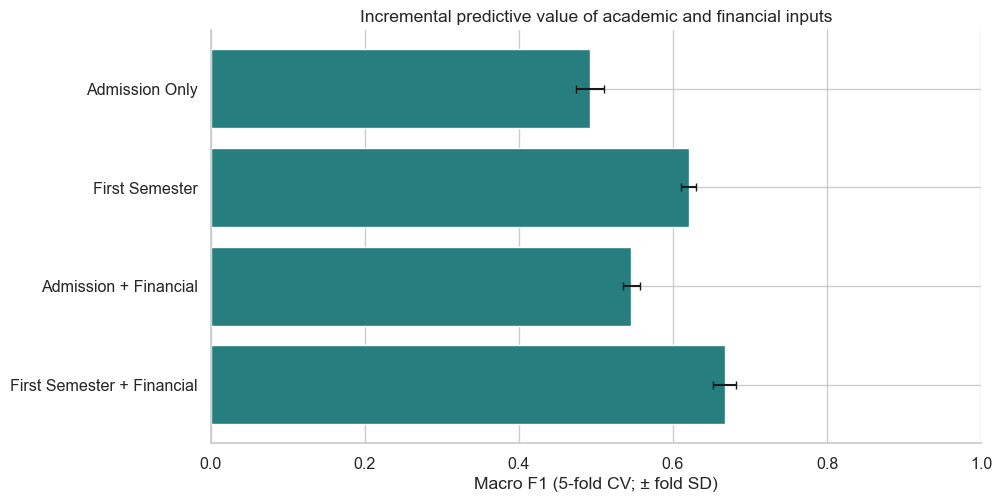

In [42]:
plt.figure(figsize=(10.2, 5.2))
plt.barh(ablation_results['Feature Set'], ablation_results['Macro F1 Mean'], xerr=ablation_results['Macro F1 Std'], color='#277e7e', capsize=3)
plt.xlim(0, 1)
plt.xlabel('Macro F1 (5-fold CV; ± fold SD)')
plt.title('Incremental predictive value of academic and financial inputs')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig(OUTPUT_DIR / '02_feature_group_ablation.png', dpi=180, bbox_inches='tight')
plt.show()


### 8.2 Reconcile repeated calculations

Export the differences between the initial and repeated Logistic Regression runs instead of silently replacing them.


In [43]:
initial_lr = comparison_results.query("Model == 'Logistic Regression'").set_index('Feature Set')
repeated_lr = ablation_results.set_index('Feature Set')
reconciliation = pd.DataFrame({
    'Initial Macro F1': initial_lr['CV f1_macro Mean'],
    'Repeated Macro F1': repeated_lr['Macro F1 Mean'],
    'Initial Dropout Recall': initial_lr['CV dropout_recall Mean'],
    'Repeated Dropout Recall': repeated_lr['Dropout Recall Mean'],
})
reconciliation['Macro F1 Difference'] = reconciliation['Repeated Macro F1'] - reconciliation['Initial Macro F1']
reconciliation.to_csv(OUTPUT_DIR / 'run_reconciliation.csv')
display(reconciliation)


,Initial Macro F1,Repeated Macro F1,Initial Dropout Recall,Repeated Dropout Recall,Macro F1 Difference
Feature Set,,,,,
Admission + Financial,0.546097,0.546097,0.597117,0.597117,0.0
Admission Only,0.492374,0.492374,0.529419,0.529419,0.0
First Semester,0.620588,0.620588,0.696561,0.696561,0.0
First Semester + Financial,0.666906,0.666906,0.751055,0.751055,0.0


## 9. Permutation importance

Importance is measured on validation folds within training data. The primary explanation uses the best tuned single model; the conditional financial explanation uses untuned Logistic Regression. Neither directly explains the ensemble or establishes causal effects. The selected hyperparameters already saw these folds during tuning.


### 9.1 Compute validation-fold importance

Shuffle original columns within training validation folds using the best tuned single model.


In [44]:
single_model_name = str(tuning_results.iloc[0]['Model'])
single_estimator = clone(tuned_pipelines[single_model_name])

def cv_permutation_importance(pipeline, set_name, repeats=N_PERM_REPEATS):
    columns = list(feature_sets[set_name])
    X_set = X_train[columns]
    rows = []
    for fold, (train_idx, val_idx) in enumerate(CV.split(X_set, y_train_encoded), start=1):
        fitted = clone(pipeline).fit(X_set.iloc[train_idx], y_train_encoded[train_idx])
        importance = permutation_importance(
            fitted, X_set.iloc[val_idx], y_train_encoded[val_idx],
            scoring='f1_macro', n_repeats=repeats, random_state=RANDOM_STATE + fold,
            n_jobs=1)
        for feat, vals in zip(columns, importance.importances):
            rows.extend({'Feature': feat, 'Fold': fold, 'Importance': float(x)} for x in vals)
        print(f'  {set_name}: finished fold {fold}/{N_SPLITS}')
    raw = pd.DataFrame(rows)
    summary = (raw.groupby('Feature')['Importance']
               .agg(Mean='mean', Std='std').sort_values('Mean', ascending=False)
               .reset_index())
    return raw, summary

print('Permutation importance for best single tuned model:', single_model_name)
primary_perm_raw, primary_importance = cv_permutation_importance(single_estimator, PRIMARY_SET)
primary_perm_raw.to_csv(OUTPUT_DIR / 'perm_primary_fold_values.csv', index=False)
primary_importance.to_csv(OUTPUT_DIR / 'perm_primary_summary.csv', index=False)
display(primary_importance.head(15).round(4))


Permutation importance for best single tuned model: Logistic Regression
  First Semester: finished fold 1/5
  First Semester: finished fold 2/5
  First Semester: finished fold 3/5
  First Semester: finished fold 4/5
  First Semester: finished fold 5/5


,Feature,Mean,Std
0,Curricular units 1st sem (approved),0.2301,0.0310
1,Curricular units 1st sem (grade),0.0388,0.0136
2,Curricular units 1st sem (enrolled),0.0352,0.0110
3,Curricular units 1st sem (evaluations),0.0350,0.0143
4,Course,0.0224,0.0090
5,Curricular units 1st sem (credited),0.0157,0.0075
6,Age at enrollment,0.0111,0.0093
7,Application mode,0.0066,0.0108
8,Father's occupation,0.0045,0.0078
9,Previous qualification,0.0044,0.0043


### 9.2 Plot primary importance

Importance describes this single model and may be shared across correlated predictors.


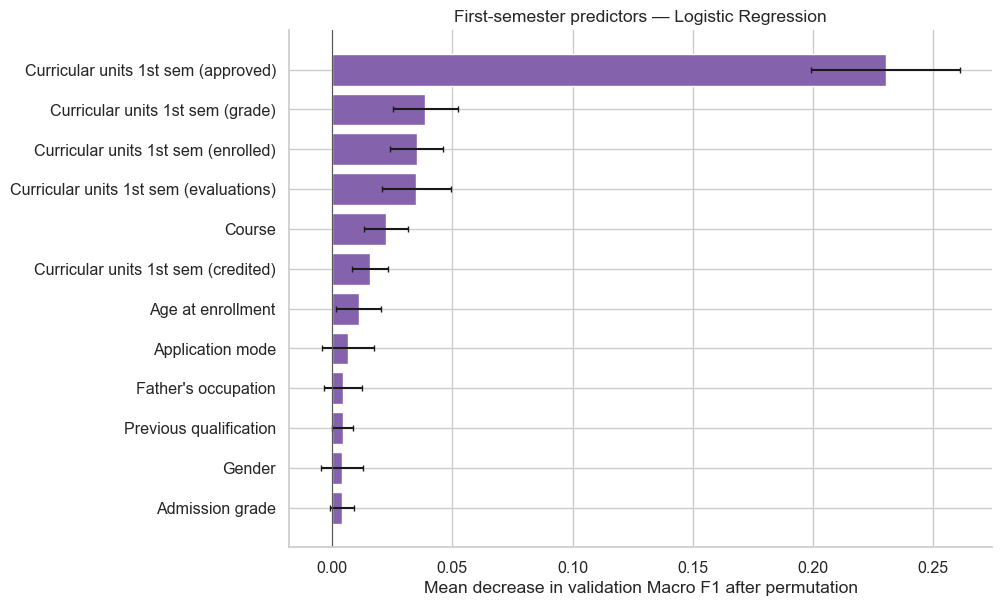

In [45]:
def plot_importance(table, title, filename, top=12):
    subset = table.head(top).iloc[::-1]
    plt.figure(figsize=(10.2, max(4, top * 0.42 + 1.2)))
    plt.barh(subset['Feature'], subset['Mean'], xerr=subset['Std'].fillna(0),
             color='#8463ac', capsize=2)
    plt.axvline(0, color='#555', linewidth=0.8)
    plt.xlabel('Mean decrease in validation Macro F1 after permutation')
    plt.title(title)
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / filename, dpi=180, bbox_inches='tight')
    plt.show()

plot_importance(primary_importance, f'First-semester predictors — {single_model_name}',
                '03_primary_feature_importance.png')


### 9.3 Conditional financial importance

Interpret an untuned Logistic Regression financial scenario; administrative timing remains unverified.


  First Semester + Financial: finished fold 1/5
  First Semester + Financial: finished fold 2/5
  First Semester + Financial: finished fold 3/5
  First Semester + Financial: finished fold 4/5
  First Semester + Financial: finished fold 5/5


,Feature,Mean,Std
0,Curricular units 1st sem (approved),0.1986,0.0243
1,Tuition fees up to date,0.0490,0.0091
2,Curricular units 1st sem (grade),0.0464,0.0096
3,Curricular units 1st sem (enrolled),0.0371,0.0117
4,Course,0.0295,0.0107
5,Curricular units 1st sem (evaluations),0.0211,0.0149
6,Application mode,0.0198,0.0114
7,Father's occupation,0.0152,0.0129
8,Curricular units 1st sem (credited),0.0143,0.0077
9,Age at enrollment,0.0099,0.0078


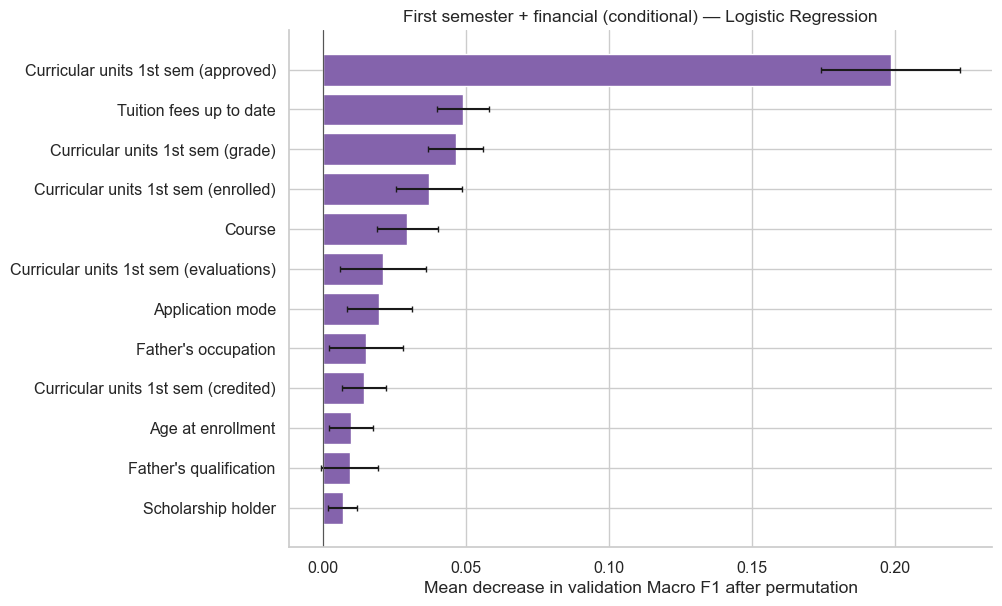

Financial feature ranks:


,Feature,Rank,Mean,Std
1,Tuition fees up to date,2,0.0490,0.0091
11,Scholarship holder,12,0.0069,0.0050
15,Debtor,16,0.0044,0.0044


In [46]:
FULL_SET = 'First Semester + Financial'
financial_pipeline = Pipeline([
    ('preprocessing', clone(preprocessors[FULL_SET])),
    ('model', LogisticRegression(max_iter=2000, random_state=RANDOM_STATE))
])
finance_perm_raw, finance_importance = cv_permutation_importance(financial_pipeline, FULL_SET)
finance_perm_raw.to_csv(OUTPUT_DIR / 'perm_financial_fold_values.csv', index=False)
finance_importance.to_csv(OUTPUT_DIR / 'perm_financial_summary.csv', index=False)
display(finance_importance.head(15).round(4))

plot_importance(finance_importance, 'First semester + financial (conditional) — Logistic Regression',
                '04_conditional_financial_importance.png')
print('Financial feature ranks:')
display(finance_importance.assign(Rank=np.arange(1, len(finance_importance) + 1))
        .query('Feature in @financial_cols')[['Feature', 'Rank', 'Mean', 'Std']].round(4))


## 10. Export report, selected configuration, and run metadata

This exports a configuration for later final evaluation, not a final test result or serialized model. Financial timing is unverified and Enrolled does not settle eventual outcomes.


### 10.1 Export computed summary

Generate a compact report from the results of this run, including explicit limitations.


In [47]:
top_features = primary_importance.head(8)['Feature'].tolist()
top_financial = finance_importance[finance_importance['Feature'].isin(financial_cols)]
report = '# Hyperparameter Tuning and Feature Importance\n\n'
report += 'Training-CV selection only; no independent test performance is calculated.\n\n'
report += '## Tuned models\n' + tuning_results.drop(columns=['Best Params']).round(4).to_markdown(index=False)
report += '\n\n## Candidate comparison\n' + candidate_results.round(4).to_markdown(index=False)
report += '\n\n## Feature-set comparison\n' + ablation_results.round(4).to_markdown(index=False)
report += '\n\n## Primary importance\n' + primary_importance.head(8).round(4).to_markdown(index=False)
report += '\n\n## Conditional financial importance\n' + top_financial.round(4).to_markdown(index=False)
report += f'\n\nProvisional winner: {WINNER_NAME}. '
report += 'CV folds were reused for tuning and selection, so results may be optimistic. '
report += 'Financial timestamps are unverified. Enrolled is unresolved. Importance is not causal. '
report += 'Independent final testing and external validation remain outstanding.\n'
(OUTPUT_DIR / 'PART_E_REPORT.md').write_text(report, encoding='utf-8')


3577

### 10.2 Export selected configuration

Save scenario, parameters, split, and CV settings for later independent evaluation.


In [48]:
params = {name: s.best_params_ for name, s in searches.items()}
handoff = {
    'selection_feature_set': PRIMARY_SET,
    'feature_columns': list(feature_sets[PRIMARY_SET]),
    'chosen_candidate': WINNER_NAME,
    'tuned_parameters': params,
    'train_test_split': {'test_size': 0.2, 'stratify': 'Target', 'random_state': RANDOM_STATE},
    'cv': {'n_splits': N_SPLITS, 'shuffle': True, 'random_state': RANDOM_STATE},
    'primary_selection_metric': 'macro F1',
    'important_note': 'CV selection only. Held-out test set NOT accessed in Tuning.',
    'financial_features_timing_verified': False,
    'fast_mode': FAST_MODE,
}
(OUTPUT_DIR / 'model_selection_for_F.json').write_text(
    json.dumps(handoff, indent=2, ensure_ascii=False), encoding='utf-8')
print('Saved', OUTPUT_DIR / 'PART_E_REPORT.md')
print('Saved', OUTPUT_DIR / 'model_selection_for_F.json')
print('Saved CSV and figures in', OUTPUT_DIR.resolve())


Saved /Users/katherine/INSY 674 Raghav/combined_results/part_e_results/PART_E_REPORT.md
Saved /Users/katherine/INSY 674 Raghav/combined_results/part_e_results/model_selection_for_F.json
Saved CSV and figures in /Users/katherine/INSY 674 Raghav/combined_results/part_e_results


### 10.3 Record the execution environment

Capture package versions and input hash when the notebook is actually run.


In [49]:
import platform
import importlib.metadata
packages = ['pandas', 'numpy', 'scipy', 'scikit-learn', 'xgboost', 'matplotlib', 'seaborn', 'ipython', 'tabulate']
versions = {}
for package in packages:
    try:
        versions[package] = importlib.metadata.version(package)
    except importlib.metadata.PackageNotFoundError:
        versions[package] = 'not installed'
run_metadata = {
    'python': platform.python_version(), 'packages': versions,
    'source': DATA_SOURCE, 'data_sha256': hashlib.sha256(DATA_BYTES).hexdigest(),
    'train_n': len(train_ids), 'test_n': len(test_ids),
    'seed': RANDOM_STATE, 'fast_mode': FAST_MODE,
    'test_performance_calculated': False,
}
(RESULTS_ROOT / 'environment_metadata.json').write_text(json.dumps(run_metadata, indent=2), encoding='utf-8')
print('Outputs:', RESULTS_ROOT)
print('Model development complete. Continue to the held-out evaluation section below.')


Outputs: /Users/katherine/INSY 674 Raghav/combined_results
Model development complete. Continue to the held-out evaluation section below.


## Sources and interpretation limits

Source files: `insy674_partb_result/PartB_EDA_Script.py`, `Part C.ipynb`, `Part_D.ipynb`, and `Part E.ipynb` in chuyu-xu/INSY674-Student-Dropout-Prediction (main, retrieved 2026-10-28). Original algorithms, search spaces, seed, metrics, and exported result filenames are retained; repeated loading, splitting, and preprocessing definitions are consolidated. Outputs are isolated under `combined_results/` so original evidence is preserved.

Financial timestamps and other input availability assumptions need confirmation. Training CV does not establish future-cohort performance, fairness, calibration, or intervention effectiveness. Final selected-model test metrics and error analysis belong to subsequent final evaluation.

Dataset: Realinho et al. (2021), *Predict Students’ Dropout and Academic Success*, UCI Machine Learning Repository, https://doi.org/10.24432/C5MC89 (CC BY 4.0).


## 11. Final held-out evaluation

Reuse the shared train/test split and the first-semester preprocessing pipeline. The frozen configuration below is the saved selection used by the verified final evaluation, rather than a new choice based on test scores. It intentionally remains fixed even if a development rerun produces slightly different CV rankings. If a genuinely new model is selected, it needs a separate validation protocol; do not optimize against this already inspected test set.

The standalone evaluation reproduced accuracy 0.7266, macro F1 0.6549, dropout precision 0.7724, and dropout recall 0.6690. These are reference values for comparison, not hard-coded predictions. Every score below is calculated by running the model.


### 11.1 Frozen configuration and shared inputs

The selected model excludes second-semester and financial indicators. All learned preprocessing is fitted on training rows only. Outputs are saved locally under `combined_results/final_evaluation/`.


In [50]:
import platform
import sklearn
import xgboost

FINAL_EVALUATION_CONFIG = json.loads(r'''{
  "selection_feature_set": "First Semester",
  "feature_columns": [
    "Marital status",
    "Application mode",
    "Application order",
    "Course",
    "Daytime/evening attendance",
    "Previous qualification",
    "Previous qualification (grade)",
    "Nacionality",
    "Mother's qualification",
    "Father's qualification",
    "Mother's occupation",
    "Father's occupation",
    "Admission grade",
    "Displaced",
    "Educational special needs",
    "Gender",
    "Age at enrollment",
    "International",
    "Curricular units 1st sem (credited)",
    "Curricular units 1st sem (enrolled)",
    "Curricular units 1st sem (evaluations)",
    "Curricular units 1st sem (approved)",
    "Curricular units 1st sem (grade)",
    "Curricular units 1st sem (without evaluations)"
  ],
  "chosen_candidate": "Soft Voting Ensemble",
  "tuned_parameters": {
    "XGBoost": {
      "model__colsample_bytree": 0.7810890415965769,
      "model__learning_rate": 0.1785436060870726,
      "model__max_depth": 4,
      "model__min_child_weight": 8,
      "model__n_estimators": 100,
      "model__reg_lambda": 0.6154014789262349,
      "model__subsample": 0.7045980821176709
    },
    "Gradient Boosting": {
      "model__learning_rate": 0.12195678219063029,
      "model__max_depth": 3,
      "model__min_samples_leaf": 12,
      "model__n_estimators": 134,
      "model__subsample": 0.9941308100323758
    },
    "Logistic Regression": {
      "model__C": 0.04480970566385288,
      "model__class_weight": "balanced"
    }
  },
  "train_test_split": {
    "test_size": 0.2,
    "stratify": "Target",
    "random_state": 42
  },
  "cv": {
    "n_splits": 5,
    "shuffle": true,
    "random_state": 42
  },
  "primary_selection_metric": "macro F1",
  "important_note": "CV selection only. Held-out test set NOT accessed in Part E.",
  "financial_features_timing_verified": false,
  "fast_mode": false
}''')
config = FINAL_EVALUATION_CONFIG
SEED = RANDOM_STATE
OUTPUT = RESULTS_ROOT / 'final_evaluation'
OUTPUT.mkdir(parents=True, exist_ok=True)
features = config['feature_columns']
assert config['chosen_candidate'] == 'Soft Voting Ensemble'
assert config['selection_feature_set'] == 'First Semester'
assert config['train_test_split'] == {'test_size': 0.2, 'stratify': 'Target', 'random_state': SEED}
assert list(features) == list(feature_sets['First Semester'])
assert len(features) == 24 and not any('2nd sem' in col for col in features)
assert not {'Scholarship holder', 'Debtor', 'Tuition fees up to date'}.intersection(features)
assert len(X_train) == 3539 and len(X_test) == 885
assert X_train.index.intersection(X_test.index).empty
encoder = LabelEncoder()
y_train_encoded = encoder.fit_transform(y_train)
y_test_encoded = encoder.transform(y_test)
class_names = encoder.classes_
class_codes = np.arange(len(class_names))
dropout_code = int(encoder.transform(['Dropout'])[0])
assert list(class_names) == ['Dropout', 'Enrolled', 'Graduate']
X_train_selected = X_train[features]
X_test_selected = X_test[features]
preprocessor = clone(preprocessors['First Semester'])


### 11.2 Rebuild the frozen ensemble and baselines

Apply the saved hyperparameters without further search or threshold changes.


In [51]:
# 4. Rebuild the selected ensemble using saved hyperparameters.
# Do not perform additional tuning using the test set.

estimators = {
    "XGBoost": XGBClassifier(
        n_estimators=150,
        random_state=SEED,
        n_jobs=1,
        tree_method="hist",
        eval_metric="mlogloss",
    ),
    "Gradient Boosting": GradientBoostingClassifier(
        random_state=SEED,
    ),
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        random_state=SEED,
    ),
}

tuned_pipelines = {}

for name, estimator in estimators.items():
    pipeline = Pipeline([
        ("preprocessing", clone(preprocessor)),
        ("model", estimator),
    ])

    pipeline.set_params(**config["tuned_parameters"][name])
    tuned_pipelines[name] = pipeline

ensemble = VotingClassifier(
    estimators=[
        ("xgb", tuned_pipelines["XGBoost"]),
        ("gb", tuned_pipelines["Gradient Boosting"]),
        ("lr", tuned_pipelines["Logistic Regression"]),
    ],
    voting="soft",
    n_jobs=1,
)

logistic_baseline = Pipeline([
    ("preprocessing", clone(preprocessor)),
    (
        "model",
        LogisticRegression(
            max_iter=2000,
            random_state=SEED,
        ),
    ),
])

models = {
    "Majority-class baseline": DummyClassifier(
        strategy="most_frequent",
    ),
    "Logistic Regression baseline": logistic_baseline,
    "Selected soft-voting ensemble": ensemble,
}


### 11.3 Train and predict held-out records

Compare the ensemble with the majority-class and untuned Logistic Regression baselines. Student-level prediction files are written locally; do not automatically publish them.


In [54]:
# 5. Fit on training records and evaluate held-out test records.

comparison_rows = []
ensemble_predictions = None

for name, model in models.items():
    print(f"\nFitting: {name}")

    # All learned preprocessing is fitted on training data only.
    model.fit(X_train_selected, y_train_encoded)
    predictions = model.predict(X_test_selected)

    comparison_rows.append({
        "Model": name,
        "Accuracy": accuracy_score(
            y_test_encoded, predictions
        ),
        "Macro F1": f1_score(
            y_test_encoded,
            predictions,
            labels=class_codes,
            average="macro",
            zero_division=0,
        ),
        "Dropout precision": precision_score(
            y_test_encoded,
            predictions,
            labels=[dropout_code],
            average="macro",
            zero_division=0,
        ),
        "Dropout recall": recall_score(
            y_test_encoded,
            predictions,
            labels=[dropout_code],
            average="macro",
            zero_division=0,
        ),
        "Dropout F1": f1_score(
            y_test_encoded,
            predictions,
            labels=[dropout_code],
            average="macro",
            zero_division=0,
        ),
    })

    prediction_table = pd.DataFrame({
        "row_index": X_test.index,
        "Actual": encoder.inverse_transform(y_test_encoded),
        "Predicted": encoder.inverse_transform(predictions),
    })

    filename = {
        "Majority-class baseline": "majority_test_predictions.csv",
        "Logistic Regression baseline": "logistic_test_predictions.csv",
        "Selected soft-voting ensemble": "test_predictions.csv",
    }[name]

    prediction_table.to_csv(OUTPUT / filename, index=False)

    if name == "Selected soft-voting ensemble":
        ensemble_predictions = predictions

comparison = pd.DataFrame(comparison_rows)
comparison.to_csv(
    OUTPUT / "test_model_comparison.csv",
    index=False,
)

print("\nHELD-OUT TEST RESULTS")
print(comparison.round(4).to_string(index=False))



Fitting: Majority-class baseline

Fitting: Logistic Regression baseline

Fitting: Selected soft-voting ensemble

HELD-OUT TEST RESULTS
                        Model  Accuracy  Macro F1  Dropout precision  Dropout recall  Dropout F1
      Majority-class baseline    0.4994    0.2221             0.0000          0.0000      0.0000
 Logistic Regression baseline    0.7153    0.6100             0.7148          0.7148      0.7148
Selected soft-voting ensemble    0.7266    0.6549             0.7724          0.6690      0.7170


### 11.4 Confusion matrix and class-level performance

Calculate the ensemble confusion matrix, precision, recall, and F1 from its actual predictions.


In [55]:
# 6. Save the final ensemble's confusion matrix and class metrics.

cm = confusion_matrix(
    y_test_encoded,
    ensemble_predictions,
    labels=class_codes,
)

cm_table = pd.DataFrame(
    cm,
    index=class_names,
    columns=class_names,
)
cm_table.index.name = "Actual"
cm_table.columns.name = "Predicted"

cm_table.to_csv(OUTPUT / "test_confusion_matrix.csv")

report = classification_report(
    y_test_encoded,
    ensemble_predictions,
    labels=class_codes,
    target_names=class_names,
    output_dict=True,
    zero_division=0,
)

report_table = pd.DataFrame(report).T
report_table.to_csv(OUTPUT / "test_classification_report.csv")

print("\nCONFUSION MATRIX")
print(cm_table)

print("\nCLASS-LEVEL PERFORMANCE")
print(report_table.round(4))



CONFUSION MATRIX
Predicted  Dropout  Enrolled  Graduate
Actual                                
Dropout        190        42        52
Enrolled        37        62        60
Graduate        19        32       391

CLASS-LEVEL PERFORMANCE
              precision  recall  f1-score   support
Dropout          0.7724  0.6690    0.7170  284.0000
Enrolled         0.4559  0.3899    0.4203  159.0000
Graduate         0.7773  0.8846    0.8275  442.0000
accuracy         0.7266  0.7266    0.7266    0.7266
macro avg        0.6685  0.6479    0.6549  885.0000
weighted avg     0.7180  0.7266    0.7189  885.0000


### 11.5 Error analysis

Count missed dropout cases and false alerts, and save detailed errors locally.


In [56]:
# 7. Calculate error counts and save individual misclassifications.

prediction_table = pd.DataFrame({
    "row_index": X_test.index,
    "Actual": encoder.inverse_transform(y_test_encoded),
    "Predicted": encoder.inverse_transform(ensemble_predictions),
})

errors = prediction_table[
    prediction_table["Actual"] != prediction_table["Predicted"]
].copy()

errors.to_csv(OUTPUT / "test_misclassified_students.csv", index=False)

error_types = (
    errors.groupby(["Actual", "Predicted"])
    .size()
    .reset_index(name="Count")
    .sort_values("Count", ascending=False)
)

error_types.to_csv(OUTPUT / "test_error_types.csv", index=False)

true_positive = int(cm[dropout_code, dropout_code])
false_negative = int(cm[dropout_code, :].sum() - true_positive)
false_positive = int(cm[:, dropout_code].sum() - true_positive)

error_summary = {
    "correctly_identified_dropout": true_positive,
    "missed_dropout": false_negative,
    "false_dropout_alerts": false_positive,
    "actual_dropout_total": int(cm[dropout_code, :].sum()),
    "predicted_dropout_total": int(cm[:, dropout_code].sum()),
}

(OUTPUT / "test_error_summary.json").write_text(
    json.dumps(error_summary, indent=2),
    encoding="utf-8",
)

print("\nERROR TYPES")
print(error_types.to_string(index=False))
print("\nDROPOUT ERROR SUMMARY")
print(json.dumps(error_summary, indent=2))



ERROR TYPES
  Actual Predicted  Count
Enrolled  Graduate     60
 Dropout  Graduate     52
 Dropout  Enrolled     42
Enrolled   Dropout     37
Graduate  Enrolled     32
Graduate   Dropout     19

DROPOUT ERROR SUMMARY
{
  "correctly_identified_dropout": 190,
  "missed_dropout": 94,
  "false_dropout_alerts": 56,
  "actual_dropout_total": 284,
  "predicted_dropout_total": 246
}


### 11.6 Verify and record the run

Check metric arithmetic, row integrity, input hashes, and the software environment.


In [57]:
# 8. Verify the calculations and record reproducibility information.

assert cm.sum() == 885
assert len(prediction_table) == 885
assert prediction_table["row_index"].is_unique

ensemble_accuracy = accuracy_score(
    y_test_encoded, ensemble_predictions
)
ensemble_macro_f1 = f1_score(
    y_test_encoded, ensemble_predictions, average="macro"
)

assert np.isclose(
    np.trace(cm) / cm.sum(),
    ensemble_accuracy,
)

assert np.isclose(
    report_table.loc[class_names, "f1-score"].mean(),
    ensemble_macro_f1,
)

pd.DataFrame({
    "row_index": X_train.index,
    "split": "train",
}).to_csv(OUTPUT / "train_row_indices.csv", index=False)

(OUTPUT / "model_selection_used.json").write_text(
    json.dumps(config, indent=2),
    encoding="utf-8",
)

metadata = {
    "python": platform.python_version(),
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "scikit-learn": sklearn.__version__,
    "xgboost": xgboost.__version__,
    "random_state": SEED,
    "training_records": len(X_train),
    "test_records": len(X_test),
    "test_class_counts": y_test.value_counts().to_dict(),
    "embedded_config_canonical_sha256": hashlib.sha256(
        json.dumps(config, sort_keys=True).encode('utf-8')
    ).hexdigest(),
    "cleaned_dataframe_csv_sha256": hashlib.sha256(
        df.to_csv(index=False).encode("utf-8")
    ).hexdigest(),
    "original_csv_sha256": hashlib.sha256(DATA_BYTES).hexdigest(),
    "note": (
        "Saved model configuration used without test-set tuning. "
        "Results may differ across software versions."
    ),
}

(OUTPUT / "evaluation_metadata.json").write_text(
    json.dumps(metadata, indent=2),
    encoding="utf-8",
)

print(f"\nAll evaluation outputs saved to: {OUTPUT.resolve()}")



All evaluation outputs saved to: /Users/katherine/INSY 674 Raghav/combined_results/final_evaluation


### 11.7 Interpretation

Use the printed test results and confusion matrix for the final report. Higher macro F1 does not guarantee higher dropout recall: compare both recall and the false-alert burden. The Enrolled label leaves eventual outcomes unresolved. This internal random split does not establish future-cohort or external performance, subgroup fairness, calibration, or intervention effectiveness.

The test set has now been used for evaluation; do not treat it as fresh validation data for another round of model selection.
